# Лекция 6. Архитектура и оценка VLM

Курс «Современное компьютерное зрение». Блокнот для Google Colab (бесплатный T4 GPU, без платных API).

Vision-language models (VLM, или мультимодальные LLM, MLLM) принимают на вход изображение и текст и генерируют текст. В лекции 5 мы разобрали CLIP: он умеет сравнивать изображение и текст, но не умеет отвечать на вопросы. Сегодня мы соединим визуальный энкодер типа CLIP или SigLIP с языковой моделью и разберём, как такую систему устроить, как уместить её в 15 ГБ видеопамяти и, главное, как честно измерить её качество.

## Цели лекции

После лекции вы сможете:

1. Нарисовать схему «визуальный энкодер → проектор → LLM» и объяснить роль каждого блока, сравнить подходы LLaVA, Qwen-VL, InternVL и SmolVLM.
2. Посчитать число визуальных токенов для заданного изображения и модели, объяснить, как модели работают с высоким разрешением и чем за это платят.
3. Оценить бюджет VRAM для инференса, объяснить квантизацию 4-bit NF4 и double quantization, реализовать memory probe с переходом с 4B на 2B.
4. Выбрать метрики для captioning, VQA и извлечения структурированных данных; понимать, что на самом деле измеряют бенчмарки и где они ломаются.
5. Использовать LLM-as-judge и проверять его на смещения.
6. Распознавать типичные ошибки VLM: галлюцинации объектов, ошибки OCR, пространственных отношений и подсчёта — и строить для них диагностические тесты.

## Содержание

Часть I. Теория

1. Что такое VLM и чем она отличается от CLIP
2. Общая схема и формализация
3. Визуальный энкодер
4. Проектор (коннектор)
5. Языковая модель и способы слияния модальностей
6. Этапы обучения
7. Семейства моделей: LLaVA, Qwen-VL, InternVL, SmolVLM
8. Высокое разрешение и число визуальных токенов
9. Бюджет VRAM и memory probe
10. Квантизация: от absmax к NF4
11. Оценка VLM: задачи и метрики
12. Бенчмарки и их ограничения
13. LLM-as-judge
14. Типичные ошибки VLM
15. Практические рекомендации

Часть II. Практика

0. Установка и конфигурация
1. Бюджет VRAM и memory probe: оценка по конфигурации, загрузка в 4-bit с проверкой памяти
2. Устройство модели: компоненты, число визуальных токенов, NF4 своими руками
3. Данные и инструменты оценки
4. Captioning: метрики и их ограничения
5. Галлюцинации: POPE и слепой тест
6. VQA с OCR: TextVQA и разрешение
7. Structured extraction: чек → JSON
8. Подсчёт объектов
9. Пространственные отношения
10. LLM-as-judge: проверяем судью
11. Переход 4B → 2B: что теряем
12. Итоги практики

Контрольные вопросы, задания и список источников — в конце блокнота.

## Как запускать

1. Откройте блокнот в Colab, выберите «Среда выполнения → Сменить среду выполнения → T4 GPU».
2. Выполните ячейки сверху вниз («Среда выполнения → Выполнить все»). Первая ячейка установит недостающие пакеты; если она попросит перезапустить среду, перезапустите и выполните всё заново.
3. Основная модель — [Qwen3-VL-4B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct) в 4-bit NF4. Если memory probe покажет нехватку памяти, блокнот сам перейдёт на [Qwen3-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct).
4. Без GPU блокнот тоже выполнится (`FAST_DEV_RUN = True`): грузится 2B в bfloat16, выборки уменьшаются. Это режим проверки кода, а не измерения качества.

Сохранённые в блокноте выводы получены в CPU-режиме на малых выборках (Qwen3-VL-2B, bfloat16, `FAST_DEV_RUN = True`). На T4 числа будут другими: модель 4B, 4-bit, выборки больше.

# Часть I. Теория

## 1. Что такое VLM и чем она отличается от CLIP

CLIP из лекции 5 — двухбашенная модель: изображение и текст независимо кодируются в векторы, а дальше мы только сравниваем векторы косинусной близостью. Такая модель отвечает на вопрос «какая из заданных подписей ближе к картинке», но не может сама написать подпись, прочитать номер на автобусе или выдать JSON с полями чека.

VLM (vision-language model, также MLLM или LMM) — генеративная модель: она получает изображение (одно или несколько, иногда видео) и текстовый запрос и порождает текст токен за токеном. Формально VLM моделирует условное распределение ответа

$$
p_\theta(y \mid I, x) = \prod_{t=1}^{T} p_\theta\bigl(y_t \mid y_{<t},\, x,\, I\bigr),
$$

где $I$ — изображение, $x$ — текстовый запрос (инструкция), $y = (y_1, \dots, y_T)$ — ответ.

Почему это важно для компьютерного зрения:

- Одна модель закрывает десятки задач, которые раньше требовали отдельных архитектур: описание изображения (captioning), ответы на вопросы (VQA), чтение текста (OCR), разбор документов и таблиц, grounding (вывод координат объектов текстом), анализ видео.
- Интерфейс задачи — текст. Новая задача часто формулируется промптом, без дообучения.
- Обратная сторона: модель всегда отвечает уверенно сформулированным текстом, даже когда «не видит». Поэтому оценка VLM — не формальность, а основная инженерная работа. Этому посвящена вторая половина лекции.

Пример. На фотографии кухни с вопросом «Сколько кружек на полке и какого они цвета?» CLIP может лишь выбрать из готовых вариантов «две красные кружки» / «три синие кружки». VLM напишет ответ сама — и может ошибиться в числе, даже правильно назвав цвет. Эти два типа ошибок (подсчёт и атрибуты) мы будем измерять отдельно.

## 2. Общая схема и формализация

Почти все открытые VLM 2023–2026 годов устроены по одной схеме, которую авторы InternVL называют ViT-MLP-LLM ([InternVL 1.5](https://arxiv.org/abs/2404.16821)):

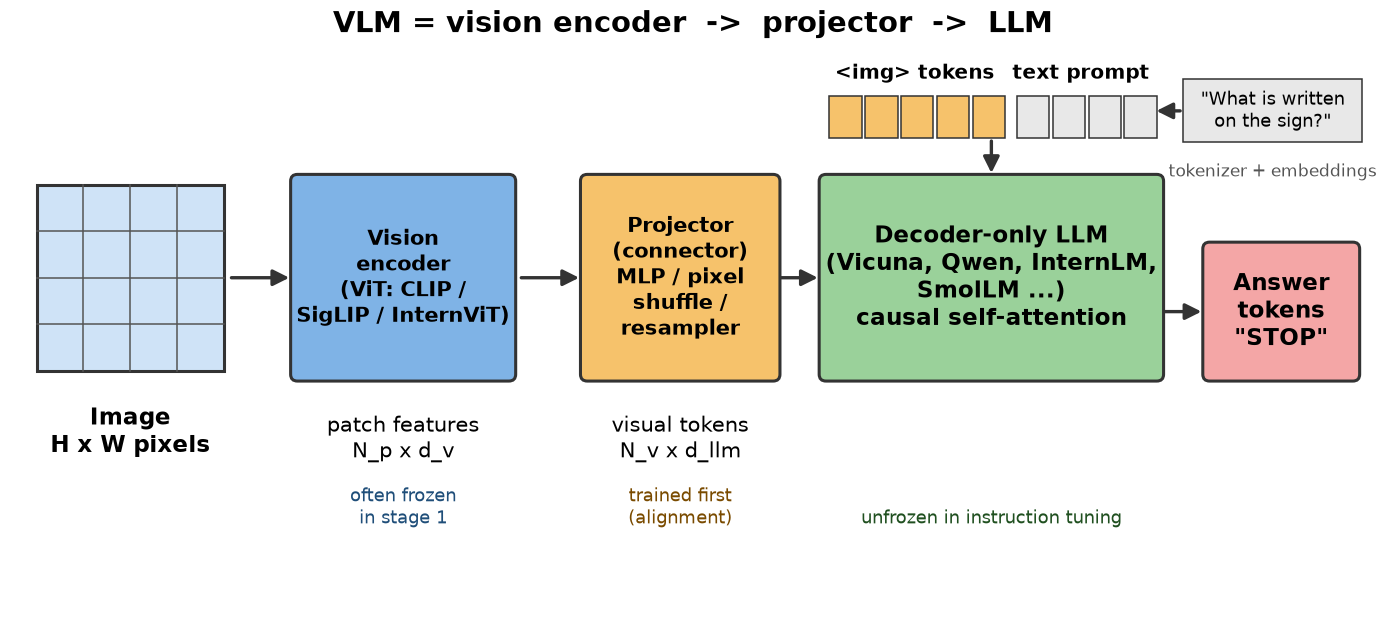

Рис. 1. Изображение режется на патчи и кодируется визуальным энкодером (ViT); проектор переводит визуальные признаки в пространство эмбеддингов LLM и, как правило, сокращает их число; полученные визуальные токены вставляются в последовательность вместе с текстовыми, и LLM генерирует ответ.

### 2.1. Три блока

1. Визуальный энкодер $E_\phi$. Обычно ViT, предобученный контрастивно (CLIP, SigLIP) или вместе с LLM (InternViT). Изображение $I \in \mathbb{R}^{H \times W \times 3}$ разбивается на патчи размера $P \times P$, и энкодер выдаёт матрицу признаков
$$
Z = E_\phi(I) \in \mathbb{R}^{N \times d_v}, \qquad N = \frac{H}{P} \cdot \frac{W}{P}.
$$
2. Проектор (коннектор, adapter) $g_\psi$. Отображает признаки в пространство эмбеддингов LLM размерности $d$ и часто сжимает их число с $N$ до $M$:
$$
V = g_\psi(Z) \in \mathbb{R}^{M \times d}.
$$
3. Языковая модель $f_\theta$ — декодер-трансформер. Её вход — последовательность эмбеддингов, где визуальные токены $V$ стоят на месте специального плейсхолдера `<image>` в шаблоне чата:
$$
H^{(0)} = \bigl[\, e(x_{1:k}),\; V,\; e(x_{k+1:n}) \,\bigr],
$$
где $e(\cdot)$ — таблица эмбеддингов текстовых токенов.

Ключевая идея: для LLM визуальные токены — просто ещё $M$ позиций в контексте. Self-attention между текстом и картинкой возникает автоматически, без новых слоёв. Это объясняет популярность схемы: можно взять готовую сильную LLM и готовый энкодер и обучить сравнительно маленький проектор.

### 2.2. Функция потерь

VLM обучают обычной авторегрессионной кросс-энтропией, но только по токенам ответа: токены изображения и инструкции маскируются.

$$
\mathcal{L}(\theta, \psi, \phi) = -\sum_{t=1}^{T} m_t \log p_\theta\bigl(y_t \mid y_{<t},\, x,\, g_\psi(E_\phi(I))\bigr),
$$

где $m_t \in \{0, 1\}$ — маска (1 для токенов ответа ассистента). Именно так обучали [LLaVA](https://arxiv.org/abs/2304.08485): в многоходовом диалоге потери считаются только по репликам ассистента.

Пример маски для одного диалога (токены условно; служебные токены шаблона чата Qwen — `im_start` и `im_end` в угловых скобках с вертикальными чертами):

| Токены | начало реплики user | визуальные токены × 196 | `What is written on the sign?` | начало реплики assistant | `STOP` | конец реплики |
|---|---|---|---|---|---|---|
| $m_t$ | 0 | 0 | 0 | 0 | 1 | 1 |

Следствие: модель не учится предсказывать «что будет на картинке», она учится отвечать на вопросы при условии картинки. Если в обучающих данных ответы часто можно угадать по тексту вопроса, модель выучит этот текстовый shortcut. Это прямая причина «слепых» успехов на бенчмарках (раздел 12) и галлюцинаций (раздел 14).

### 2.3. Стоимость в токенах

Если в запросе $n_{\text{txt}}$ текстовых токенов, $M$ визуальных и генерируется $T$ токенов, то:

- prefill (обработка всего промпта за один проход) стоит примерно $2 P_{\text{LLM}} (n_{\text{txt}} + M)$ FLOP плюс квадратичная часть attention $\propto L (n_{\text{txt}} + M)^2 d$;
- каждый шаг генерации читает все веса LLM и весь KV-кэш длины $n_{\text{txt}} + M + t$.

Визуальных токенов обычно на порядок больше, чем текстовых: вопрос — 10–30 токенов, картинка — от 64 до нескольких тысяч. Поэтому число визуальных токенов $M$ — главный рычаг скорости и памяти VLM. В практике (раздел 2.2) мы измерим, что на CPU время prefill растёт почти линейно с $M$.

## 3. Визуальный энкодер

### 3.1. Какие энкодеры используют

| Энкодер | Как обучен | Где используется |
|---|---|---|
| CLIP ViT-L/14, 224 или 336 px | контрастивно на парах картинка–текст | [LLaVA](https://arxiv.org/abs/2304.08485), [LLaVA-1.5](https://arxiv.org/abs/2310.03744) |
| OpenCLIP ViT-bigG, 1.9B | контрастивно | [Qwen-VL](https://arxiv.org/abs/2308.12966) |
| SigLIP / SigLIP 2 | контрастивно с сигмоидной функцией потерь | [SmolVLM](https://arxiv.org/abs/2504.05299), [Qwen3-VL](https://arxiv.org/abs/2511.21631) |
| InternViT-300M / 6B | контрастивно, затем дообучение вместе с LLM | [InternVL 1.5](https://arxiv.org/abs/2404.16821), [InternVL3](https://arxiv.org/abs/2504.10479) |
| ViT 675M с 2D-RoPE | обучен под нативное разрешение | [Qwen2-VL](https://arxiv.org/abs/2409.12191) |

Почему именно контрастивные энкодеры: их признаки уже выровнены с языком (лекция 5), поэтому проектору нужно выучить сравнительно простое отображение. Энкодеры, обученные чисто на изображениях (DINOv2, лекция 4), дают лучшие локальные признаки, но хуже согласованы с текстом; их иногда добавляют вторым энкодером.

### 3.2. Какие признаки берут

- Обычно берут выход предпоследнего слоя ViT, а не последнего: последний слой сильнее «заточен» под контрастивную задачу и хуже сохраняет локальные детали. Авторы [LLaVA](https://arxiv.org/abs/2304.08485) сравнивали признаки сетки до и после последнего слоя трансформера.
- Токен [CLS] обычно не используют: нужна вся сетка патчей, иначе пропадает пространственная информация.
- В [Qwen3-VL](https://arxiv.org/abs/2511.21631) применён DeepStack: признаки нескольких промежуточных слоёв ViT (у 2B — слои 5, 11 и 17, см. практику) через отдельные мерджеры добавляются в первые слои LLM. Так LLM получает и низкоуровневые, и семантические признаки.

### 3.3. Ограничение: CLIP-слепота

Если энкодер не различает два изображения, никакая LLM после него их не различит. [MMVP](https://arxiv.org/abs/2401.06209) собирает «CLIP-blind pairs» — пары изображений, которые CLIP считает почти одинаковыми, хотя визуально они явно различаются (ориентация, количество, наличие мелкой детали, положение камеры). На 300 вопросах по 9 паттернам ошибок многие VLM, включая GPT-4V, отвечали хуже человека, а ошибки VLM коррелировали со слабостями энкодера CLIP. Вывод для практики: ошибки в подсчёте и ориентации часто рождаются в энкодере, а не в LLM, и не лечатся промптом.

## 4. Проектор (коннектор)

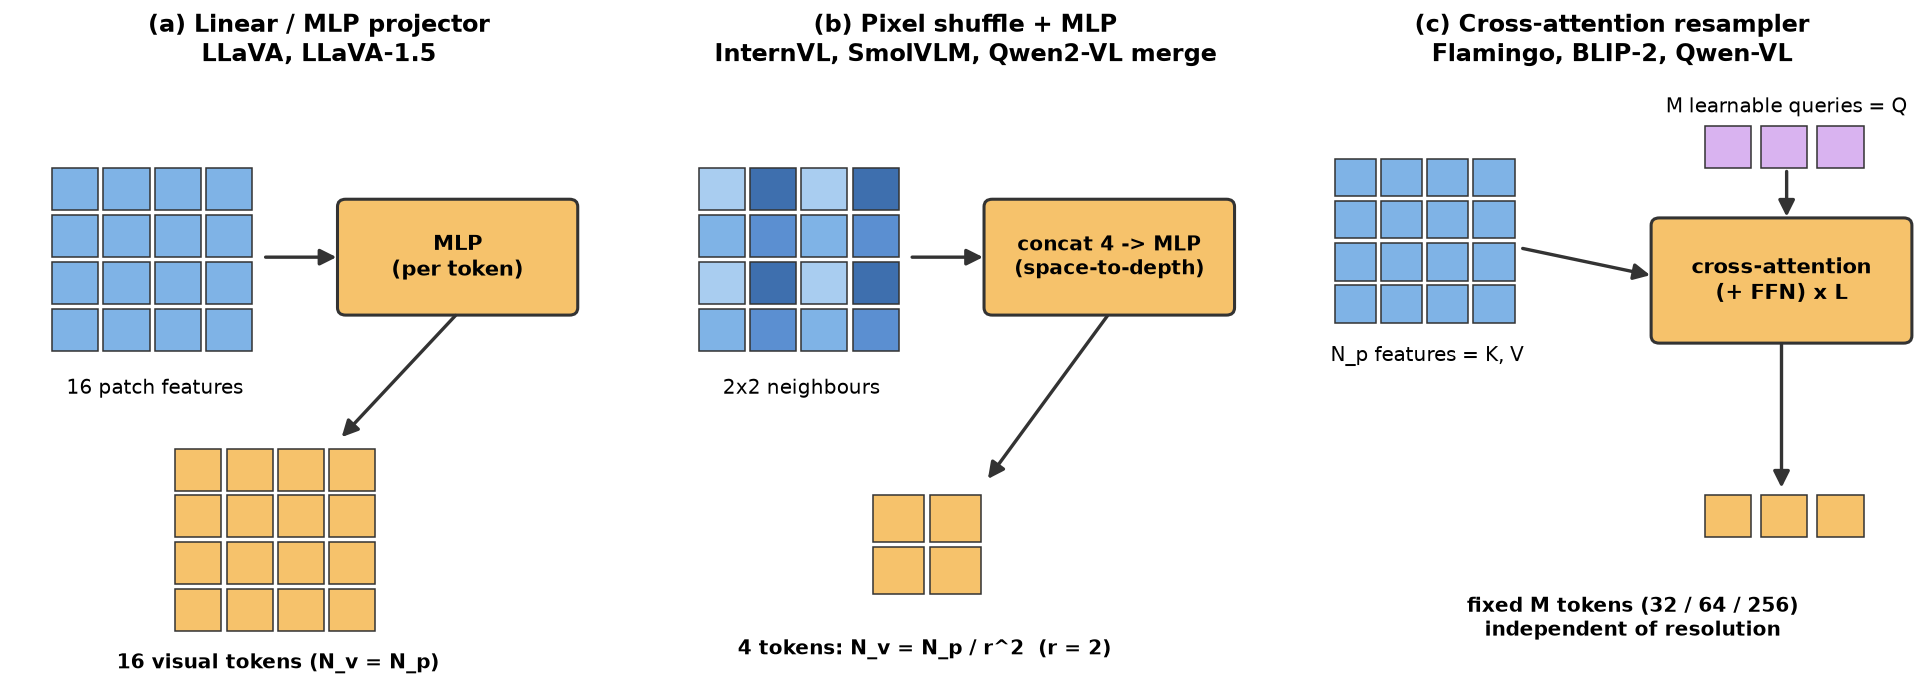

Рис. 2. Три семейства коннекторов: линейный слой или MLP сохраняет число токенов; pixel shuffle объединяет соседние токены, сокращая их в $r^2$ раз; Q-Former и Perceiver Resampler сжимают картинку до фиксированного числа обучаемых запросов.

### 4.1. Линейный слой и MLP

Простейший вариант — линейное отображение, как в первой [LLaVA](https://arxiv.org/abs/2304.08485):

$$
V = Z W, \qquad W \in \mathbb{R}^{d_v \times d}.
$$

[LLaVA-1.5](https://arxiv.org/abs/2310.03744) заменила его двухслойным MLP, и это одно из изменений, давших заметный рост качества:

$$
V = W_2\, \mathrm{GELU}(Z W_1).
$$

Число токенов не меняется: $M = N$. Для CLIP ViT-L/14 с входом 336×336 получаем $(336/14)^2 = 24^2 = 576$ визуальных токенов.

### 4.2. Слияние соседних токенов: pixel shuffle и 2×2 merge

Чтобы сократить число токенов без потери информации о соседстве, объединяют блок $r \times r$ соседних признаков в один вектор (space-to-depth, pixel unshuffle) и затем применяют MLP:

$$
Z \in \mathbb{R}^{h \times w \times d_v} \;\longrightarrow\; Z' \in \mathbb{R}^{\frac{h}{r} \times \frac{w}{r} \times r^2 d_v} \;\xrightarrow{\text{MLP}}\; V \in \mathbb{R}^{\frac{hw}{r^2} \times d}.
$$

- [InternVL 1.5](https://arxiv.org/abs/2404.16821): тайл 448×448, патч 14, получаем $32 \times 32 = 1024$ признака, pixel shuffle с $r = 2$ оставляет четверть — 256 токенов на тайл.
- [Qwen2-VL](https://arxiv.org/abs/2409.12191): MLP сливает 2×2 соседних токена; картинка 224×224 при патче 14 превращается в 66 токенов (64 + 2 служебных).
- Qwen3-VL: патч 16 и слияние 2×2, то есть один визуальный токен покрывает 32×32 пикселя.
- [SmolVLM](https://arxiv.org/abs/2504.05299): авторы показали, что маленьким моделям выгоден агрессивный pixel shuffle $r = 4$ (в 16 раз меньше токенов), тогда как InternVL и Idefics3 используют $r = 2$.

Пример. Изображение 512×512 в SigLIP-B/16 даёт $32^2 = 1024$ патча. При $r = 2$ это 256 токенов, при $r = 4$ — 64 токена. Для LLM на 135M параметров и короткого контекста разница между 1024 и 64 токенами решает, поместится ли в контекст хоть что-то кроме одной картинки.

### 4.3. Обучаемые запросы: Q-Former и Perceiver Resampler

Третий подход — набор из $K$ обучаемых векторов-запросов $Q \in \mathbb{R}^{K \times d_q}$, которые через cross-attention «вытягивают» информацию из признаков энкодера:

$$
V = \mathrm{CrossAttn}(Q,\; Z) = \mathrm{softmax}\!\left(\frac{Q W_Q (Z W_K)^\top}{\sqrt{d_k}}\right) Z W_V .
$$

Число выходных токенов равно $K$ независимо от разрешения.

- [BLIP-2](https://arxiv.org/abs/2301.12597): Q-Former на 188M параметров с 32 запросами размерности 768.
- [Flamingo](https://arxiv.org/abs/2204.14198): Perceiver Resampler выдаёт фиксированные 64 визуальных выхода для любого размера карты признаков или числа кадров.
- [Qwen-VL](https://arxiv.org/abs/2308.12966): однослойный cross-attention адаптер (0.08B) с обучаемыми запросами сжимает картинку 448×448 до 256 токенов.

Плюс: фиксированная и малая длина. Минус: сжатие с потерями, плохо для OCR и мелких деталей, и такие коннекторы сложнее обучать. Начиная с Qwen2-VL, семейство Qwen отказалось от фиксированных запросов в пользу слияния 2×2 и динамического разрешения.

### 4.4. Сравнение

| Коннектор | Токенов на выходе | Сохраняет геометрию | Пример |
|---|---|---|---|
| Linear / MLP | $N$ | да | LLaVA, LLaVA-1.5 |
| Pixel shuffle / 2×2 merge + MLP | $N / r^2$ | да, грубее | InternVL, Qwen2/2.5/3-VL, SmolVLM |
| Q-Former / Resampler | $K$ (фиксировано) | частично | BLIP-2, Flamingo, Qwen-VL |

## 5. Языковая модель и способы слияния модальностей

Схема «токены в контекст» (late fusion через вход LLM) — не единственная.

1. Визуальные токены во входной последовательности. LLaVA, InternVL, Qwen2/2.5-VL, SmolVLM. Просто, совместимо с любыми оптимизациями LLM (KV-кэш, FlashAttention), но дорого по длине контекста.
2. Cross-attention слои внутри LLM. [Flamingo](https://arxiv.org/abs/2204.14198) вставляет между замороженными слоями LLM новые блоки GATED XATTN-DENSE с гейтом $\tanh(\alpha)$:
$$
y \leftarrow y + \tanh(\alpha_{\text{xattn}}) \cdot \mathrm{Attn}(q = y,\; kv = V), \qquad y \leftarrow y + \tanh(\alpha_{\text{dense}}) \cdot \mathrm{FFW}(y).
$$
При $\alpha = 0$ в начале обучения LLM работает как исходная, и обучение стартует плавно. Визуальные токены не занимают контекст, но нужны новые слои.
3. Многоуровневая инъекция. DeepStack в [Qwen3-VL](https://arxiv.org/abs/2511.21631): основные визуальные токены идут на вход, а признаки промежуточных слоёв ViT прибавляются к скрытым состояниям первых слоёв LLM на тех же позициях. Длина контекста не растёт, а LLM получает больше визуальных деталей.
4. Нативная мультимодальность (early fusion). Модель с самого начала предобучается на смеси текста и изображений, а не «прикручивает» зрение к готовой LLM. [InternVL3](https://arxiv.org/abs/2504.10479) называет это native multimodal pretraining; малые модели [Qwen3.5](https://huggingface.co/unsloth/Qwen3.5-4B) (0.8B–9B, март 2026) заявлены как нативно мультимодальные с ранним слиянием ([анонс Qwen](https://x.com/Alibaba_Qwen/status/2028460046510965160)).

### 5.1. Позиционное кодирование визуальных токенов

Если просто вытянуть сетку $h \times w$ в строку, LLM видит одномерные позиции и должна сама восстановить, что токен $i$ и токен $i + w$ — соседи по вертикали. Решения:

- обучаемые позиционные эмбеддинги в энкодере и специальные токены строк и тайлов (SmolVLM показала пользу обучаемых позиционных токенов, [SmolVLM](https://arxiv.org/abs/2504.05299));
- M-RoPE в [Qwen2-VL](https://arxiv.org/abs/2409.12191): rotary-кодирование раскладывается на три компоненты — время, высота, ширина; для текста все три равны, для картинки высота и ширина берутся из координат токена в сетке;
- interleaved MRoPE в [Qwen3-VL](https://arxiv.org/abs/2511.21631): частоты для t, h, w чередуются по всей размерности, чтобы каждая ось получала и высокие, и низкие частоты.

Пространственные рассуждения VLM (раздел 14.3) во многом упираются именно в то, насколько хорошо геометрия сохранена в позиционных кодах и в проекторе.

## 6. Этапы обучения

Типичный рецепт состоит из двух–четырёх стадий.

| Стадия | Что обучается | Данные | Пример |
|---|---|---|---|
| 1. Выравнивание (alignment, pretraining проектора) | только проектор | пары картинка–подпись | LLaVA: 595K пар, отфильтрованных из CC3M ([LLaVA](https://arxiv.org/abs/2304.08485)) |
| 2. Мультимодальное предобучение | проектор + энкодер и/или LLM | сотни миллионов–миллиарды пар, interleaved-документы, OCR | Qwen-VL, InternVL, Qwen3-VL |
| 3. Instruction tuning (SFT) | проектор + LLM (часто и энкодер) | диалоги, VQA, документы, grounding | LLaVA: 158K инструкций, сгенерированных GPT-4 |
| 4. Выравнивание по предпочтениям / RL | LLM | пары предпочтений, задачи с проверяемым ответом | Cascade RL в [InternVL3.5](https://arxiv.org/abs/2508.18265) |

Факты о масштабе:

- [LLaVA-1.5](https://arxiv.org/abs/2310.03744) обучалась на 1.2M общедоступных примеров примерно за сутки на одном узле с 8 A100 и достигла state of the art на 11 бенчмарках на момент выхода.
- [Qwen3-VL](https://arxiv.org/abs/2511.21631) начинает с warm-up стадии, где обучается только мерджер, а энкодер и LLM заморожены, затем размораживает всё и наращивает контекст до 256K токенов.

Пример, почему стадия 1 нужна. Если сразу обучать всю систему, случайно инициализированный проектор подаёт в LLM «шум» в пространстве эмбеддингов, градиенты от такого входа портят уже обученные веса LLM. Короткое выравнивание проектора на простых подписях ставит визуальные токены в «осмысленную» область пространства эмбеддингов, после чего размораживать LLM безопаснее.

## 7. Семейства моделей

### 7.1. LLaVA

- [LLaVA](https://arxiv.org/abs/2304.08485) (2023): CLIP ViT-L/14 + линейный слой + Vicuna. Главный вклад — идея генерировать мультимодальные инструкции с помощью текстовой GPT-4 по подписям и рамкам объектов (158K примеров).
- [LLaVA-1.5](https://arxiv.org/abs/2310.03744): CLIP-ViT-L-336px, двухслойный MLP, академические VQA-данные с промптами формата ответа («Answer the question using a single word or phrase»), 576 визуальных токенов. Вариант LLaVA-1.5-HD режет изображение на сетку тайлов.
- [LLaVA-NeXT](https://llava-vl.github.io/blog/2024-01-30-llava-next/) (2024): в 4 раза больше пикселей, разрешения 672×672, 336×1344, 1344×336; техника AnyRes выбирает сетку тайлов из {2×2, 1×{2,3,4}, {2,3,4}×1} и добавляет уменьшенную копию всего изображения.

LLaVA важна как минимальная воспроизводимая архитектура: на ней удобно объяснять и проверять почти любую идею.

### 7.2. Qwen-VL

- [Qwen-VL](https://arxiv.org/abs/2308.12966) (2023): ViT-bigG 1.9B, cross-attention адаптер со сжатием до 256 токенов, вход 448×448, всего 9.6B параметров.
- [Qwen2-VL](https://arxiv.org/abs/2409.12191) (2024): naive dynamic resolution — картинка обрабатывается в исходном разрешении (с округлением сторон), число токенов зависит от размера; M-RoPE; размеры 2B, 7B, 72B.
- [Qwen2.5-VL](https://arxiv.org/abs/2502.13923) (2025): window attention в ViT — только 4 слоя с полным вниманием, остальные внутри окон 112×112 (8×8 патчей), что делает стоимость энкодера почти линейной по числу патчей.
- [Qwen3-VL](https://arxiv.org/abs/2511.21631) (2025): плотные 2B/4B/8B/32B и MoE-варианты, энкодер SigLIP-2 (SigLIP2-Large 300M для 2B и 4B), MLP-мерджер 2×2, DeepStack, interleaved MRoPE, текстовые временные метки для видео, контекст 256K.

В практике используются [Qwen3-VL-4B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct) и [Qwen3-VL-2B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct). По конфигурациям моделей (практика, раздел 1.1): у 2B — LLM со скрытой размерностью 2048 и 28 слоями, у 4B — 2560 и 36 слоёв; визуальная часть вместе с мерджерами около 0.4B параметров в обоих случаях.

### 7.3. InternVL

- [InternVL 1.5](https://arxiv.org/abs/2404.16821): InternViT-6B + InternLM2-20B, динамическое высокое разрешение — изображение режется на тайлы 448×448 по подходящему соотношению сторон, плюс миниатюра всего изображения; pixel shuffle до 256 токенов на тайл.
- [InternVL3](https://arxiv.org/abs/2504.10479): InternViT-300M или 6B, нативное мультимодальное предобучение, V2PE (variable visual position encoding) для длинных мультимодальных контекстов; InternVL3-78B — 72.2 на MMMU.
- [InternVL3.5](https://arxiv.org/abs/2508.18265): от 1B до 241B параметров, Cascade RL, Visual Resolution Router (ViR) в Flash-версиях выбирает для каждого патча 256 или 64 токена, Decoupled Vision-Language Deployment (DvD) — энкодер и LLM на разных GPU.

### 7.4. SmolVLM

[SmolVLM](https://arxiv.org/abs/2504.05299) (2025) — семейство для ограниченных устройств:

| Модель | Энкодер | LLM | VRAM на инференсе |
|---|---|---|---|
| SmolVLM-256M | SigLIP-B/16, 93M | SmolLM2-135M | 0.8 ГБ |
| SmolVLM-500M | SigLIP-B/16, 93M | SmolLM2-360M | 1.2 ГБ |
| SmolVLM-2.2B | SigLIP-SO400M, 400M | SmolLM2-1.7B | 4.9 ГБ |

Для сравнения, в той же статье Qwen2-VL-2B требует 13.7 ГБ, InternVL2-2B — 10.5 ГБ. Разница почти целиком объясняется числом визуальных токенов: SmolVLM агрессивно сжимает изображение (pixel shuffle $r = 4$), а модели Qwen и InternVL тратят много токенов на высокое разрешение. Выводы авторов полезны как чек-лист для малых моделей: сбалансировать размер энкодера и LLM, увеличить контекст, сильнее сжимать токены, использовать обучаемые позиционные токены, не переиспользовать текстовые SFT-данные LLM.

### 7.5. Сводная таблица

| Модель | Энкодер | Коннектор | Разрешение | Токенов на изображение (пример) |
|---|---|---|---|---|
| LLaVA-1.5 | CLIP ViT-L/14-336 | MLP | фиксированное 336² | 576 |
| LLaVA-NeXT | CLIP ViT-L/14-336 | MLP | AnyRes, до 672² | до 5 × 576 = 2880 |
| Qwen-VL | ViT-bigG | cross-attn, 256 запросов | 448² | 256 |
| Qwen2-VL | ViT 675M | MLP 2×2 | нативное | 224² → 66 |
| Qwen3-VL | SigLIP-2 | MLP 2×2 + DeepStack | нативное, 32 px на токен | 448² → 196; 1344×896 → 1176 |
| InternVL 1.5–3.5 | InternViT | pixel shuffle + MLP | тайлы 448² + миниатюра | 256 на тайл |
| SmolVLM | SigLIP | pixel shuffle $r = 4$ + линейный | тайлы 512² | 64 на тайл |

Число 2880 для LLaVA-NeXT получено так: сетка 2×2 тайлов 336² плюс уменьшенная копия, по 576 токенов. Числа для Qwen3-VL вычислены по правилу 32 пикселя на токен и проверены в практике.

## 8. Высокое разрешение и число визуальных токенов

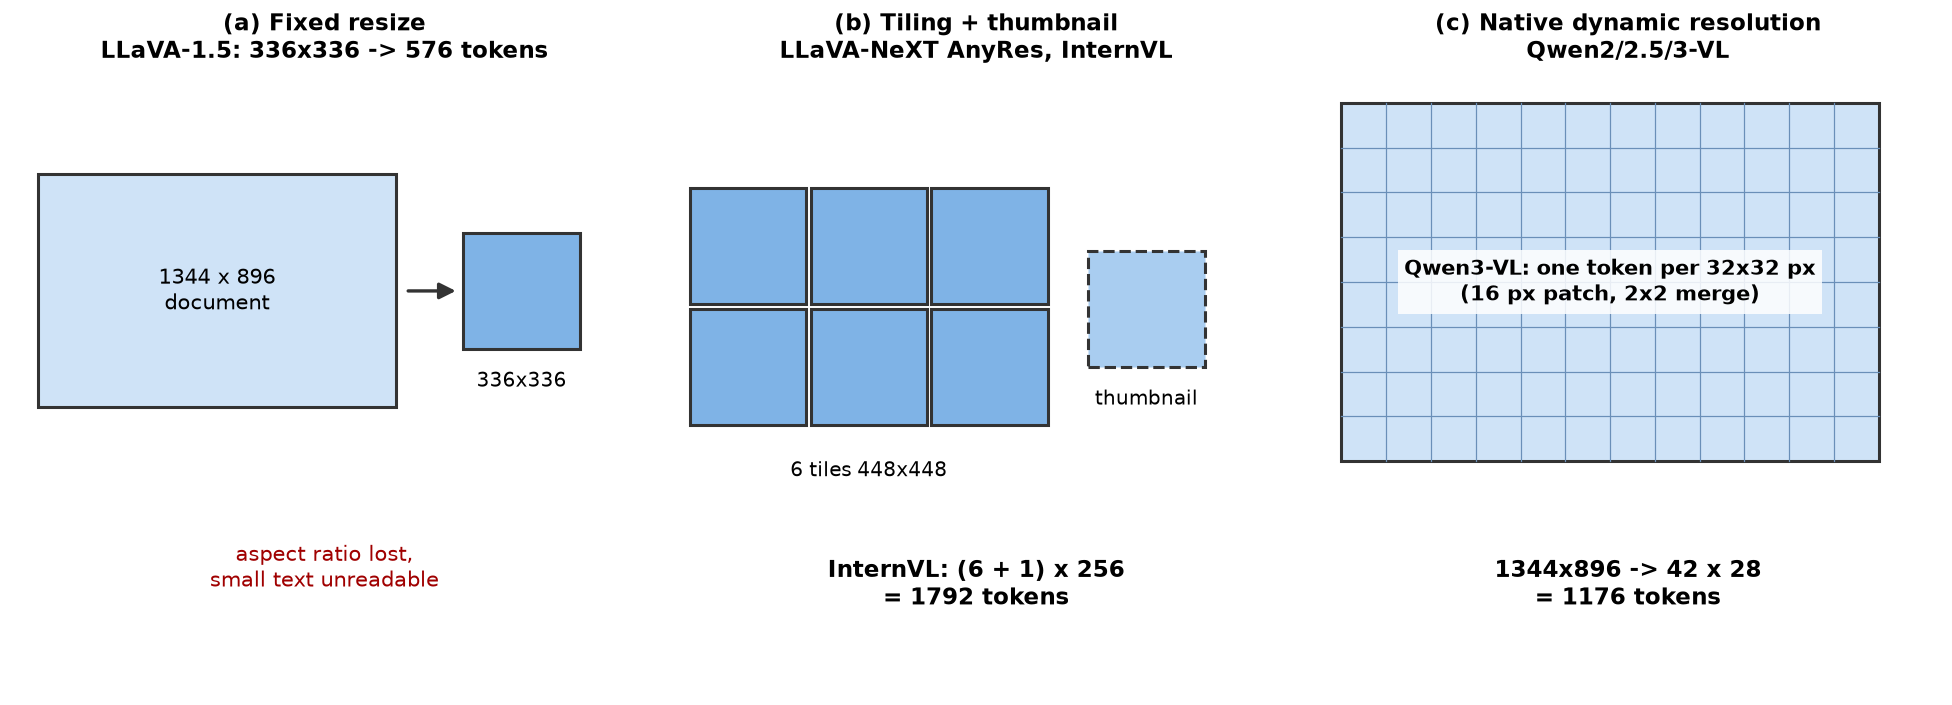

Рис. 3. (a) Фиксированный ресайз — всё изображение сжимается до 336×336, мелкий текст теряется. (b) Разбиение на тайлы + миниатюра — каждый тайл кодируется в родном для энкодера разрешении. (c) Нативное динамическое разрешение — изображение режется на патчи как есть, число токенов пропорционально площади.

### 8.1. Почему разрешение критично

Энкодер CLIP обучен на 224 или 336 пикселях. Документ A4 при 300 dpi — это 2480×3508 пикселей. Сжатие до 336×336 уменьшает каждую сторону в 7–10 раз: буква высотой 30 пикселей становится высотой 3 пикселя, и прочитать её невозможно никакой моделью. Поэтому OCR, документы, графики и мелкие объекты требуют высокого разрешения, а captioning общих сцен — почти нет.

### 8.2. Формулы числа токенов

Фиксированный ресайз: $M = (S / P)^2 / r^2$, где $S$ — сторона входа энкодера.

Тайлы (InternVL, LLaVA-NeXT): выбирается сетка $a \times b$ тайлов, ближайшая по соотношению сторон к изображению (при ограничении $ab \le n_{\max}$), плюс миниатюра:

$$
M = (a b + 1) \cdot m_{\text{tile}}, \qquad m_{\text{tile}} = \frac{(S/P)^2}{r^2}.
$$

Нативное разрешение (Qwen2-VL и новее): стороны округляются до кратного $P \cdot r$ (у Qwen3-VL это $16 \cdot 2 = 32$), и

$$
M = \frac{H'}{P r} \cdot \frac{W'}{P r},
$$

где $H', W'$ — округлённые размеры, а общее число пикселей зажимается в диапазон $[\text{min\_pixels}, \text{max\_pixels}]$ с сохранением пропорций.

### 8.3. Примеры расчёта

| Изображение | LLaVA-1.5 | InternVL (тайлы 448, $n_{\max} = 6$) | Qwen3-VL (32 px на токен) |
|---|---|---|---|
| 448×448 | 576 | 1 тайл + миниатюра = 512 | $14 \times 14 = 196$ |
| 1344×896 (3:2) | 576 | сетка 3×2 + миниатюра = $7 \times 256 = 1792$ | $42 \times 28 = 1176$ |
| A4, 2480×3508 | 576 | ограничено $n_{\max}$: 6 тайлов + 1 = 1792 | $\approx 2480 \cdot 3508 / 32^2 \approx 8500$ |

Расчёт для InternVL с одним тайлом предполагает, что миниатюра добавляется всегда, когда тайлов больше одного; в реализациях InternVL при единственном тайле миниатюру обычно не добавляют, тогда будет 256. Это хороший пример того, почему числа токенов нужно проверять в коде процессора, а не выводить из статьи.

Что видно из таблицы:

- для маленьких изображений нативное разрешение экономнее фиксированного ресайза: Qwen3-VL тратит на 448² втрое меньше токенов, чем LLaVA-1.5;
- для документов нативное разрешение без ограничения быстро выходит за любые бюджеты. Поэтому на практике всегда задают `max_pixels` (в блокноте — через `MAX_VISUAL_TOKENS`, по умолчанию 1024 токена, то есть примерно 1 мегапиксель).

### 8.4. Стоимость высокого разрешения

Удвоение стороны изображения увеличивает число токенов в 4 раза. Последствия:

1. Prefill LLM дорожает примерно пропорционально $M$ (линейная часть) и $M^2$ (attention). Для 4B-модели при 1176 визуальных токенах линейная часть — порядка $2 \cdot 4 \cdot 10^9 \cdot 1176 \approx 10^{13}$ FLOP, то есть доли секунды на T4 с пиковыми 65 TFLOPS в FP16 ([NVIDIA T4](https://www.nvidia.com/en-us/data-center/tesla-t4/)) и минуты на CPU.
2. Энкодер работает на патчах до слияния: у Qwen3-VL их в 4 раза больше, чем визуальных токенов (1176 токенов = 4704 патча). Полное внимание в ViT квадратично по числу патчей, поэтому Qwen2.5-VL перешла на window attention.
3. KV-кэш растёт линейно с $M$ (раздел 9).
4. Для видео всё умножается на число кадров.

Способы экономии: ограничение `max_pixels`; динамический выбор числа токенов по содержанию (ViR в [InternVL3.5](https://arxiv.org/abs/2508.18265)); подход «scale then compress» в [NVILA](https://arxiv.org/abs/2412.04468) — сначала поднять разрешение, затем агрессивно сжать токены; кадрирование интересующей области (crop) перед вторым проходом модели.

Пример решения инженерной задачи. Нужно читать номера контейнеров на фото 4000×3000. Подать изображение целиком в Qwen3-VL при лимите 1024 токена значит сжать его до примерно 1 Мп, то есть в 12 раз по площади, — номер высотой 60 пикселей станет высотой около 17 пикселей. Лучше сначала найти область номера детектором или первым проходом VLM с запросом координат, затем вырезать её и подать отдельно. В практике (раздел 6) мы измерим, как точность чтения текста зависит от бюджета токенов и размера шрифта.

## 9. Бюджет VRAM и memory probe

### 9.1. Из чего складывается память на инференсе

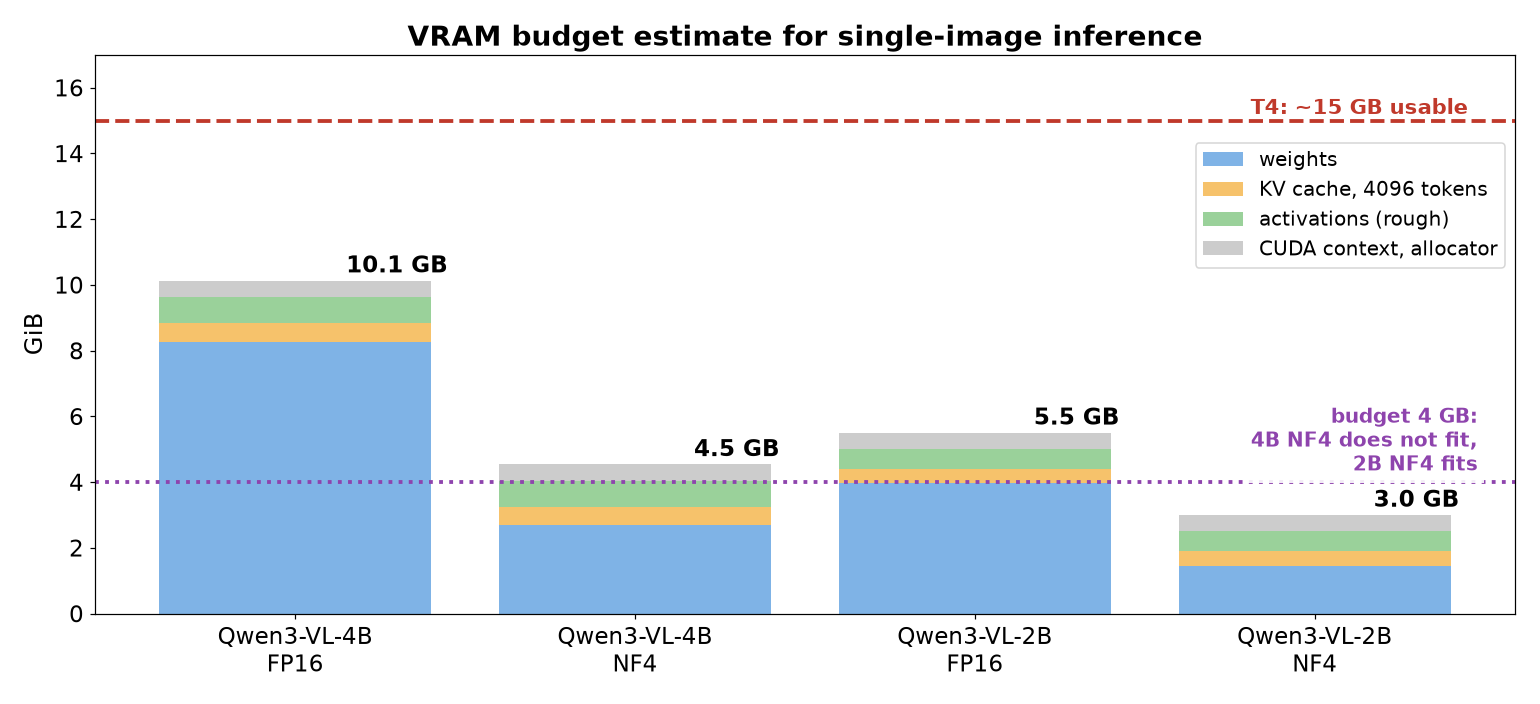

Рис. 5. Оценка памяти для инференса одной картинки: веса в разных форматах, KV-кэш, активации и служебная память CUDA. На T4 с 15 ГиБ доступной памяти 4B в FP16 помещается впритык, в 4-bit — с большим запасом.

$$
\text{VRAM} \approx \underbrace{\sum_j n_j\, b_j}_{\text{веса}} + \underbrace{\text{KV}(L_{\text{ctx}})}_{\text{кэш}} + \underbrace{A_{\text{peak}}}_{\text{активации}} + \underbrace{C_{\text{CUDA}}}_{\text{контекст, аллокатор}},
$$

где $n_j$ — число параметров в группе $j$, $b_j$ — байт на параметр (FP16/BF16 — 2, INT8 — 1, NF4 — примерно 0.5 плюс константы квантования).

KV-кэш. Для каждого слоя и каждого токена хранятся ключи и значения всех KV-голов:

$$
\text{KV} = 2 \cdot n_{\text{layers}} \cdot n_{\text{kv}} \cdot d_{\text{head}} \cdot b \cdot L_{\text{ctx}}.
$$

Пример для Qwen3-VL-2B (28 слоёв, 8 KV-голов, $d_{\text{head}} = 128$, FP16):
$$
2 \cdot 28 \cdot 8 \cdot 128 \cdot 2 = 114\,688 \ \text{байт} = 112\ \text{КиБ на токен}.
$$
Для 4B (36 слоёв) — 144 КиБ на токен. Запрос с картинкой 1344×896 (1176 визуальных токенов), 50 токенами текста и ответом на 256 токенов занимает около 1500 позиций, то есть примерно 210 МиБ кэша у 4B. Это немного по сравнению с весами; но для пакета из 16 запросов или видео из 32 кадров кэш становится главным потребителем памяти. Grouped-query attention (8 KV-голов вместо 16–32 голов запросов) уменьшает кэш в 2–4 раза.

Веса. По конфигурации (практика, раздел 1.1) Qwen3-VL-4B имеет около 4.44B параметров: в FP16 это 8.27 ГиБ, в NF4 — около 2.7 ГиБ, потому что часть модулей (эмбеддинги, нормализации, иногда выходной слой) остаётся в 16 битах. Независимое измерение даёт 2.62 ГБ для 4B в 4-bit ([пример запуска Qwen3-VL-4B](https://seanneilan.com/posts/scraping-target-with-qwen/)).

Активации. На prefill пик определяется самым большим промежуточным тензором: MLP-проекция LLM ($L_{\text{ctx}} \times d_{\text{ff}}$), матрица внимания ViT, если используется «eager»-реализация внимания (для 4704 патчей и 16 голов это $16 \cdot 4704^2 \cdot 2$ байт ≈ 0.7 ГБ), логиты на словарь в 150K токенов. Поэтому оценка «веса + кэш» всегда занижена, и её нужно проверять измерением.

### 9.2. Особенности Colab T4

- 16 ГБ GDDR6, 65 TFLOPS в смешанной точности FP16/FP32 ([спецификация NVIDIA T4](https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/tesla-t4/t4-tensor-core-datasheet-951643.pdf)); после резервирования драйвером и контекстом CUDA доступно около 15 ГиБ.
- Архитектура Turing (compute capability 7.5) не поддерживает BF16 в тензорных ядрах: в спецификации перечислены FP32, FP16, INT8 и INT4. Поэтому на T4 вычисления ведут в FP16 (`bnb_4bit_compute_dtype=torch.float16`), а на A100/L4/H100 — в BF16. FP16 имеет узкий диапазон (максимум 65504), что иногда даёт переполнения и NaN; если модель на T4 выдаёт пустые или повторяющиеся строки, это первое, что нужно проверить.
- 4-bit загрузка на T4 работает и для 7B-моделей: например, Qwen2.5-VL-7B в NF4 профилировали на T4 ([vlm-inference-profiler](https://github.com/varuntej07/vlm-inference-profiler)).

### 9.3. Memory probe и переход 4B → 2B

Оценка по формулам — необходимое, но недостаточное условие. Надёжный способ — memory probe: перед основной работой выполнить самый тяжёлый ожидаемый запрос и измерить пик памяти.

Алгоритм, реализованный в практике:

1. Для каждого кандидата из списка `[4B, 2B]`:
   1. загрузить модель в 4-bit NF4; при `OutOfMemoryError` на загрузке перейти к следующему кандидату;
   2. сбросить счётчик пика (`torch.cuda.reset_peak_memory_stats()`), выполнить probe: изображение на максимальный бюджет визуальных токенов (`MAX_VISUAL_TOKENS`) и генерацию с максимальной длиной ответа;
   3. если пик плюс запас (например, 1 ГиБ на фрагментацию и пакетные запросы) не превышает бюджет — модель выбрана;
   4. иначе выгрузить модель, очистить кэш (`gc.collect()`, `torch.cuda.empty_cache()`) и перейти к следующему кандидату.
2. Если не подошёл ни один кандидат — уменьшить `MAX_VISUAL_TOKENS` и повторить.

Чтобы проверить ветку перехода на 2B на T4, где 4B помещается, в практике можно задать искусственный бюджет `VRAM_BUDGET_GB`: функция `torch.cuda.set_per_process_memory_fraction` ограничивает аллокатор PyTorch, и probe 4B падает с нехваткой памяти, как на более слабой видеокарте.

Почему 4B → 2B, а не 4B в 16 битах или 8B в 4 битах. В рамках одного семейства и одного процессора изображений смена размера модели меняет только LLM-часть: визуальные токены, шаблон чата и формат ответа остаются теми же, поэтому весь протокол оценки переносится без изменений. Цена перехода — качество рассуждений и устойчивость к формату; в практике (раздел 11) мы её измерим на тех же задачах.

Пример решения. Бюджет 6 ГиБ (ноутбучная видеокарта). Веса 4B в NF4 — около 2.7 ГиБ, кэш на 1500 токенов — 0.2 ГиБ, контекст CUDA — 0.3–0.5 ГиБ, пик активаций на prefill 1176 визуальных токенов — 1–2 ГиБ. Итого 4.5–5.5 ГиБ: 4B проходит, но без запаса на пакеты. Если нужно обрабатывать пакеты по 8 изображений, логичнее взять 2B или снизить `MAX_VISUAL_TOKENS` до 512.

## 10. Квантизация: от absmax к NF4

### 10.1. Зачем и что квантуют

Квантизация хранит веса в малом числе бит. Для инференса VLM на бесплатном GPU это способ уместить 4B-модель в несколько гигабайт. Квантуют обычно только веса линейных слоёв (weight-only quantization); активации и вычисления остаются в FP16/BF16.

### 10.2. Absmax-квантизация

Для блока весов $w \in \mathbb{R}^B$ и $k$ бит:

$$
c = \frac{\max_i |w_i|}{2^{k-1} - 1}, \qquad q_i = \mathrm{round}\!\left(\frac{w_i}{c}\right), \qquad \hat{w}_i = c\, q_i .
$$

Проблема — выбросы. Один большой по модулю вес растягивает шкалу, и почти все остальные значения попадают в несколько центральных уровней. Решения:

- блочная квантизация: своя константа $c$ на блок из 64 весов, тогда выброс портит только свой блок;
- [LLM.int8()](https://arxiv.org/abs/2208.07339): начиная примерно с 6.7B параметров в активациях появляются систематические выбросы в отдельных измерениях; метод выполняет эти измерения в FP16, а остальное — в INT8.

### 10.3. NormalFloat-4 (NF4)

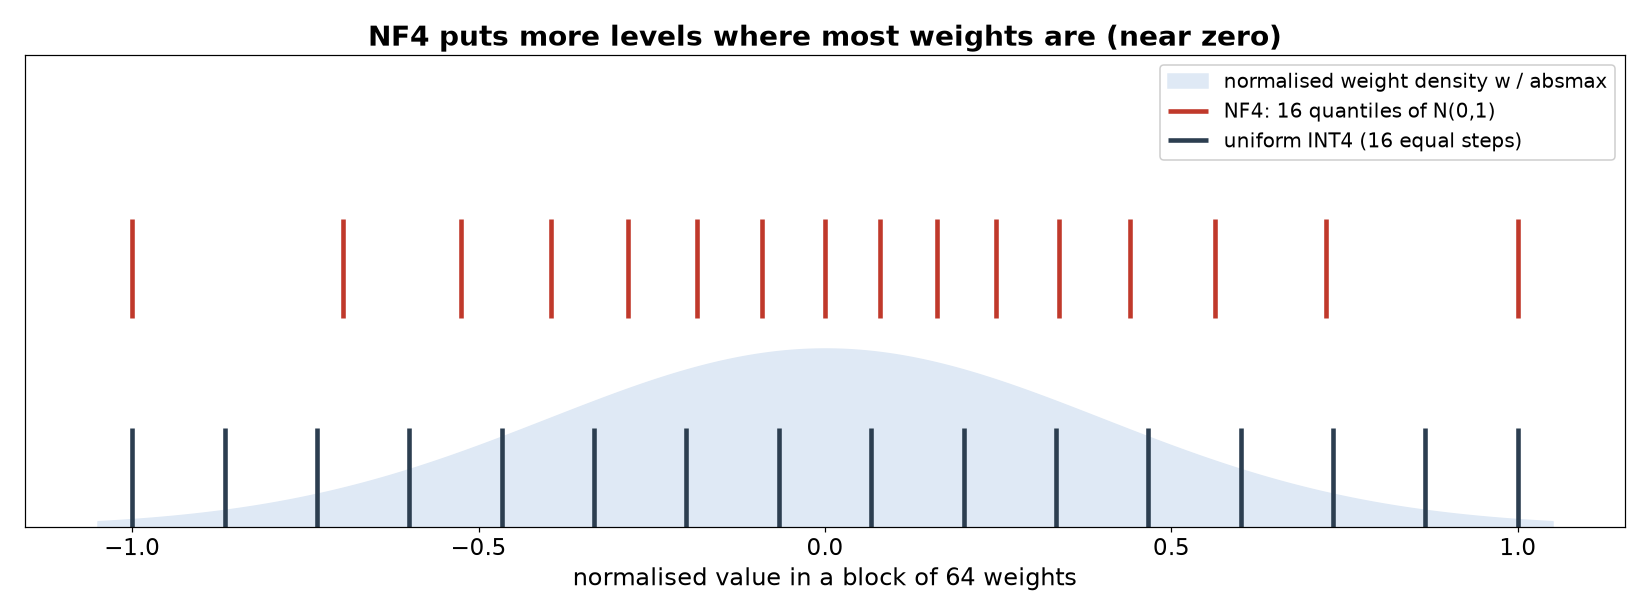

Рис. 4. Уровни NF4 расставлены по квантилям нормального распределения: у нуля, где сосредоточено большинство весов, уровни гуще, на хвостах — реже. Равномерная 4-битная сетка тратит много уровней на редкие большие значения.

Наблюдение [QLoRA](https://arxiv.org/abs/2305.14314): предобученные веса приблизительно нормальны с нулевым средним. Если веса нормализованы в $[-1, 1]$ делением на absmax блока, оптимальные для такого распределения уровни — квантили $\mathcal{N}(0, 1)$. Каждый уровень тогда получает примерно одинаковую долю весов (квантование с максимальной энтропией).

Построение 16 уровней NF4:

1. Чтобы ноль представлялся точно, уровни строятся несимметрично: 8 положительных и 7 отрицательных квантилей плюс ноль.
2. Квантили берутся с отступом $\delta \approx 0.9677$, чтобы не получить $\pm\infty$:
$$
q^{+}_j = \Phi^{-1}\!\left(\frac{1}{2} + \frac{j}{8} \cdot \Bigl(\delta - \frac{1}{2}\Bigr)\right), \quad j = 1..8; \qquad q^{-}_j = -\Phi^{-1}\!\left(\frac{1}{2} + \frac{j}{7} \cdot \Bigl(\delta - \frac{1}{2}\Bigr)\right), \quad j = 1..7,
$$
затем к ним добавляется ноль и всё нормируется делением на максимум, чтобы крайние уровни были $\pm 1$. Именно так уровни строятся в функции [`create_normal_map` библиотеки bitsandbytes](https://github.com/bitsandbytes-foundation/bitsandbytes/blob/main/bitsandbytes/functional.py); в практике мы повторим это построение и сверим уровни.
3. Получаем уровни (округлённо): $-1, -0.696, -0.525, -0.395, -0.284, -0.185, -0.091, 0, 0.080, 0.161, 0.246, 0.338, 0.441, 0.563, 0.723, 1$.

Квантование блока: $c = \max_i |w_i|$, каждый $w_i / c$ заменяется индексом ближайшего уровня (4 бита), хранится $c$. Деквантование: $\hat{w}_i = c \cdot \mathrm{NF4}[q_i]$.

Пример на четырёх числах. Блок $w = (0.02, -0.15, 0.30, 0.01)$, $c = 0.30$, нормированные значения $(0.067, -0.5, 1, 0.033)$. Ближайшие уровни NF4: $0.080, -0.525, 1, 0$ — восстановленные веса $(0.024, -0.158, 0.30, 0)$. Равномерная 4-битная absmax-сетка с шагом $1/7$ (уровни $0, \pm 0.143, \dots$) дала бы $(0, -0.171, 0.30, 0)$: оба маленьких веса обнулились бы, а ошибка среднего веса выросла бы с 0.008 до 0.021. NF4 точнее именно там, где весов больше всего.

В практике (раздел 2.3) мы квантуем настоящий слой Qwen3-VL и сравним ошибку и энтропию индексов для равномерной INT4 и NF4.

### 10.4. Double quantization

Константы $c$ тоже занимают память. При блоке 64 и 32-битной константе это $32 / 64 = 0.5$ бита на параметр, то есть 12.5% к 4 битам. [QLoRA](https://arxiv.org/abs/2305.14314) квантует сами константы в 8-битные float блоками по 256, и накладные расходы падают до

$$
\frac{8}{64} + \frac{32}{64 \cdot 256} \approx 0.127 \ \text{бита на параметр},
$$

экономия около 0.37 бита на параметр (примерно 3 ГБ для 65B-модели). Для 4B-модели это около 0.2 ГБ — немного, но на T4 запас лишним не бывает. В `transformers` это `bnb_4bit_use_double_quant=True`.

### 10.5. Что важно понимать о скорости

- Bitsandbytes хранит веса в 4 битах, но перед матричным умножением деквантует их в `compute_dtype` (FP16 или BF16). Квантизация экономит память и пропускную способность памяти, но не ускоряет арифметику. На prefill (вычислительно ограниченный режим) 4-bit часто медленнее FP16 из-за деквантования; на генерации по одному токену (ограничение пропускной способностью памяти) выигрыш или паритет возможны.
- Квантизация — не бесплатная: обычно потеря качества у NF4 мала для больших моделей и заметнее для малых. Для VLM чувствительнее всего задачи, требующие точности, — OCR и подсчёт. Квантовать визуальный энкодер и мерджер рискованнее, чем LLM; в `BitsAndBytesConfig` есть параметр `llm_int8_skip_modules`, чтобы оставить отдельные модули в 16 битах.

### 10.6. Другие методы

| Метод | Идея | Когда использовать |
|---|---|---|
| NF4 (bitsandbytes) | квантили нормального распределения, без калибровки | быстрый старт, QLoRA-дообучение |
| [LLM.int8()](https://arxiv.org/abs/2208.07339) | INT8 + выбросы в FP16 | когда 4 бита теряют слишком много |
| [GPTQ](https://arxiv.org/abs/2210.17323) | послойная квантизация с компенсацией ошибки по приближённой информации второго порядка; модели на 175B квантуются примерно за 4 GPU-часа | продакшн-инференс со специальными ядрами |
| [AWQ](https://arxiv.org/abs/2306.00978) | защита 0.1–1% «важных» каналов весов, выбранных по величине активаций, через масштабирование | продакшн-инференс, хорошее качество на 4 битах |

GPTQ и AWQ требуют калибровочных данных и дают готовые квантованные чекпоинты с быстрыми ядрами; NF4 квантует «на лету» при загрузке.

## 11. Оценка VLM: задачи и метрики

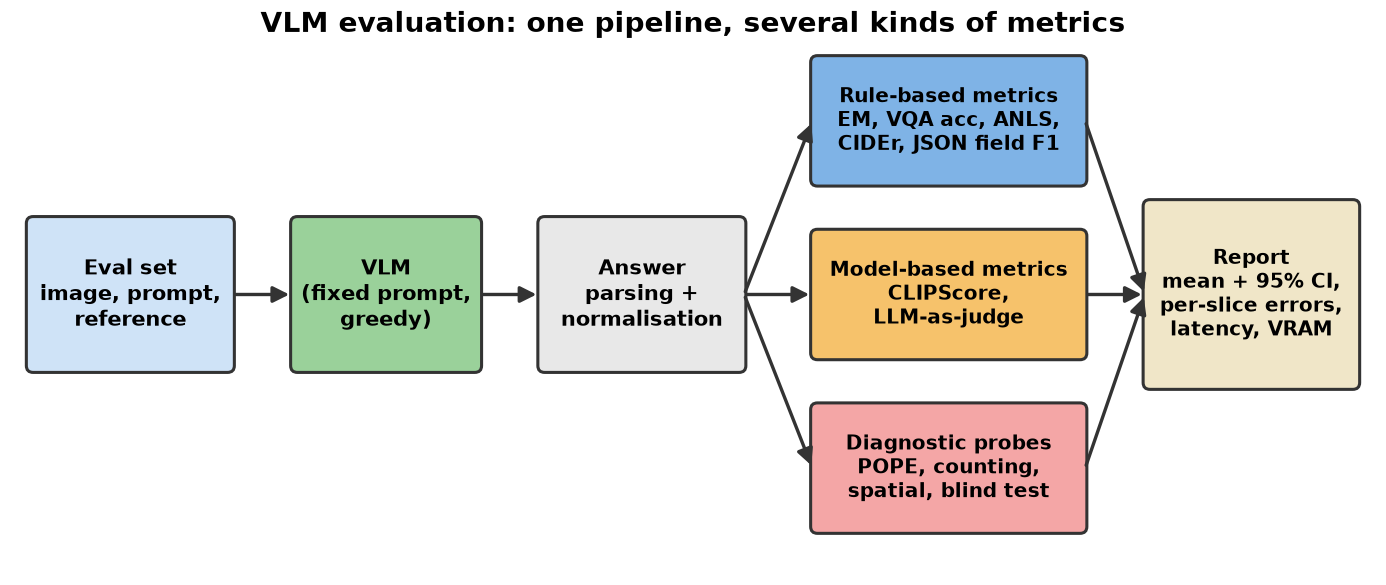

Рис. 6. Один и тот же конвейер — данные, промпт, генерация, нормализация ответа — заканчивается разными метриками в зависимости от типа задачи.

Общее правило: метрика должна соответствовать формату ответа. Свободный текст оценивают по сходству с эталонами или судьёй, короткий ответ — точным совпадением после нормализации, структурированный — по полям.

### 11.1. Captioning

BLEU, METEOR, ROUGE — n-граммное сходство с эталонами, пришедшее из машинного перевода.

CIDEr ([Vedantam et al.](https://arxiv.org/abs/1411.5726)). Каждая подпись представляется вектором TF-IDF весов n-грамм $g^n(\cdot)$, и считается среднее косинусное сходство кандидата $c$ с эталонами $s_1, \dots, s_m$:

$$
\mathrm{CIDEr}_n(c, S) = \frac{1}{m} \sum_{j=1}^{m} \frac{g^n(c) \cdot g^n(s_j)}{\lVert g^n(c) \rVert \, \lVert g^n(s_j) \rVert}, \qquad \mathrm{CIDEr}(c, S) = \frac{1}{4}\sum_{n=1}^{4} \mathrm{CIDEr}_n .
$$

IDF понижает вес n-грамм, встречающихся в подписях ко многим изображениям («a man», «in the»), и повышает вес специфичных. CIDEr-D добавляет штраф за разницу длин и ограничение счётчиков n-грамм, а итог умножается на 10. Важно: IDF считается по всему корпусу эталонов, поэтому CIDEr на 20 изображениях и на 5000 — разные числа.

CLIPScore ([Hessel et al.](https://arxiv.org/abs/2104.08718)) — метрика без эталонов:

$$
\mathrm{CLIPScore}(I, c) = w \cdot \max\bigl(\cos(E_I(I),\, E_T(\text{"A photo depicts "} + c)),\; 0\bigr), \qquad w = 2.5 .
$$

SPICE сравнивает графы сцен (объекты, атрибуты, отношения), извлечённые из подписей; лучше коррелирует с людьми, но требует Java-парсера.

Ограничения метрик captioning, которые мы увидим в практике:

- Эталонные подписи Flickr8k и COCO короткие (около 10–12 слов). Подробное правильное описание из 80 слов получает низкий CIDEr, потому что большинство его n-грамм отсутствует в эталонах. Метрики штрафуют стиль, а не ошибки.
- CLIPScore ограничен 77 токенами текстового энкодера CLIP и почти не чувствителен к подсчёту и отношениям — CLIP сам их плохо различает (лекция 5).
- Ни одна n-граммная метрика не ловит галлюцинации надёжно: «a dog on a red sofa» и «a dog on a blue sofa» различаются одним словом.

Хорошая практика: считать метрику и для одной человеческой подписи относительно остальных четырёх (human baseline). Если модель получает CIDEr ниже, чем человек, это ещё не значит, что она хуже: может просто отличаться стиль.

### 11.2. Галлюцинации объектов: CHAIR и POPE

CHAIR ([Rohrbach et al.](https://arxiv.org/abs/1809.02156)) проверяет упоминания объектов в подписи по разметке COCO:

$$
\mathrm{CHAIR}_i = \frac{|\{\text{упомянутые объекты, которых нет на изображении}\}|}{|\{\text{все упомянутые объекты}\}|}, \qquad \mathrm{CHAIR}_s = \frac{|\{\text{подписи хотя бы с одной галлюцинацией}\}|}{|\{\text{все подписи}\}|}.
$$

POPE ([Li et al.](https://arxiv.org/abs/2305.10355)) задаёт бинарные вопросы «Is there a \<object\> in the image?» и считает accuracy, precision, recall, F1 и долю ответов «yes». Отрицательные объекты выбираются тремя способами:

- random — случайный объект из словаря COCO;
- popular — самые частые объекты датасета;
- adversarial — объекты, чаще всего встречающиеся вместе с присутствующими (на фото кухни спрашиваем про холодильник, которого нет).

Авторы взяли 500 изображений COCO с более чем тремя объектами и по 6 вопросов на изображение и обнаружили, что ранние VLM (LLaVA, MultiModal-GPT, mPLUG-Owl) отвечали «yes» почти на все вопросы. Поэтому доля «yes» — обязательная часть отчёта: модель, отвечающая «yes» всегда, получает 50% accuracy и 100% recall.

### 11.3. VQA

VQA accuracy ([Antol et al.](https://arxiv.org/abs/1505.00468)). На каждый вопрос 10 ответов людей; ответ модели $a$ после нормализации (регистр, артикли, пунктуация, числа словами) получает

$$
\mathrm{Acc}(a) = \min\!\left(\frac{\#\{\text{люди, ответившие } a\}}{3},\; 1\right),
$$

в официальной реализации усреднённое по всем подмножествам из 9 ответов из 10. Совпадение хотя бы с тремя людьми даёт полный балл.

ANLS ([DocVQA](https://arxiv.org/abs/2007.00398)) — мягкая метрика для текстовых ответов, прощающая мелкие ошибки распознавания:

$$
\mathrm{ANLS} = \frac{1}{N}\sum_{i=1}^{N} \max_j s(a_i, g_{ij}), \qquad s(a, g) = \begin{cases} 1 - \mathrm{NL}(a, g), & \mathrm{NL}(a, g) < \tau \\ 0, & \text{иначе} \end{cases}, \quad \tau = 0.5,
$$

где $\mathrm{NL}$ — расстояние Левенштейна, нормированное на длину большей строки. Ответ «STQP» на эталон «STOP» получает $1 - 1/4 = 0.75$ вместо нуля в точном совпадении.

CER (character error rate) для чистого OCR: $\mathrm{CER} = \mathrm{Lev}(a, g) / |g|$.

Множественный выбор и CircularEval ([MMBench](https://arxiv.org/abs/2307.06281)). Вопрос с $N$ вариантами задаётся $N$ раз с циклически сдвинутыми вариантами, и он засчитывается, только если все $N$ ответов верны. Это убирает выигрыш от позиционного смещения («всегда A») и от угадывания: у случайной модели вероятность пройти 4 сдвига — $(1/4)^4 \approx 0.4\%$ вместо 25%.

Слепой baseline. Те же вопросы задаются без изображения (или с серой картинкой). Разница «с картинкой минус без» показывает, сколько качества дают именно визуальные данные. В практике слепой baseline есть для POPE и TextVQA.

### 11.4. Structured extraction

Задача: по изображению документа (чек, счёт, паспорт, накладная) выдать JSON заданной схемы. Метрики иерархические:

1. Валидность JSON: доля ответов, которые удалось разобрать (после извлечения из блока кода).
2. Соответствие схеме: все ли обязательные ключи на месте, правильные ли типы.
3. Точность полей: для каждого поля — точное совпадение после нормализации (числа как числа, даты в ISO, суммы с допуском 0.01).
4. Списки (позиции чека): сопоставление позиций (по названию или венгерским алгоритмом) и precision, recall, F1 на уровне позиций:
$$
P = \frac{|\hat{Y} \cap Y|}{|\hat{Y}|}, \quad R = \frac{|\hat{Y} \cap Y|}{|Y|}, \quad F_1 = \frac{2PR}{P + R}.
$$
5. Арифметическая согласованность: совпадает ли сумма позиций с итогом. Это проверка без эталона, полезная в продакшне.

Почему не одна метрика «JSON совпал целиком»: она слишком строгая (одна опечатка обнуляет пример) и не показывает, где модель ошибается. В практике мы генерируем синтетические чеки с известной истиной и считаем все пять уровней.

### 11.5. Протокол оценки

Без этого числа несравнимы:

- фиксированные промпты (включая системный) и шаблон чата;
- детерминированная генерация (`do_sample=False`), фиксированный `max_new_tokens`;
- фиксированный бюджет визуальных токенов (`max_pixels`);
- одинаковая нормализация ответов;
- доверительные интервалы: на 100 примерах стандартная ошибка доли около 0.5 составляет $\sqrt{0.25 / 100} = 5$ процентных пунктов, то есть разница в 3 пункта между моделями — шум. В практике интервалы считаются бутстрепом.

## 12. Бенчмарки и их ограничения

### 12.1. Основные бенчмарки

| Бенчмарк | Что измеряет | Объём и формат | Метрика |
|---|---|---|---|
| [MMMU](https://arxiv.org/abs/2311.16502) | экспертные знания с изображениями | 11.5K вопросов, 30 предметов, 183 подобласти | accuracy; GPT-4V 56%, Gemini Ultra 59% на момент выхода |
| [MMBench](https://arxiv.org/abs/2307.06281) | широкий набор восприятия и рассуждений | множественный выбор | CircularEval |
| [MME](https://arxiv.org/abs/2306.13394) | восприятие и познание | 14 подзадач, по 2 вопроса да/нет на изображение | accuracy и accuracy+ (оба вопроса верны) |
| [MMStar](https://arxiv.org/abs/2403.20330) | задачи, действительно требующие изображения | 1500 отобранных примеров | accuracy |
| [MathVista](https://arxiv.org/abs/2310.02255) | математика по графикам, диаграммам | 6141 пример из 28 датасетов + 3 новых | accuracy |
| [TextVQA](https://arxiv.org/abs/1904.08920) | чтение текста в сценах | 45 336 вопросов на 28 408 изображениях | VQA accuracy |
| [DocVQA](https://arxiv.org/abs/2007.00398) | документы | 50 000 вопросов, 12 000+ документов | ANLS |
| [OCRBench](https://arxiv.org/abs/2305.07895) | OCR в разных условиях | 29 датасетов, 1000 пар вопрос–ответ, 5 задач | доля верных |
| [POPE](https://arxiv.org/abs/2305.10355) | галлюцинации объектов | вопросы да/нет | accuracy, F1, доля «yes» |
| [BLINK](https://arxiv.org/abs/2404.12390) | базовое восприятие (глубина, соответствия, отражения) | 14 задач | accuracy; люди 95.7% |

Инструменты: [VLMEvalKit](https://arxiv.org/abs/2407.11691) и [lmms-eval](https://arxiv.org/abs/2407.12772) реализуют десятки бенчмарков с единым интерфейсом. Пользоваться ими полезно, но промпты и парсинг ответов у разных инструментов различаются, и одна модель может получить разные числа.

### 12.2. Ограничения

1. Утечка и текстовые shortcut. [MMStar](https://arxiv.org/abs/2403.20330) показала, что многие вопросы решаются без изображения: GeminiPro набирает 42.9% на MMMU без картинок, а Sphinx-X-MoE без изображений получает на MMMU 43.6% при 17.9% у его LLM-основы — то есть модель запомнила ответы во время мультимодального обучения. Слепой baseline обязателен.
2. Насыщение. На популярных бенчмарках лучшие модели упираются в шум разметки, и разница в 1 пункт ничего не говорит.
3. Формат вместо знания. Модель может «знать» ответ, но выдать его не в том формате: «The answer is two» вместо «2». Результат зависит от парсера.
4. Множественный выбор упрощает задачу. Выбор из четырёх вариантов проще, чем генерация, и поддаётся позиционным смещениям — отсюда CircularEval.
5. Несоответствие задаче. Высокий MMMU не гарантирует, что модель прочитает номер накладной на вашем фото. Для продукта нужен собственный тестовый набор из 100–300 примеров реальных данных с разметкой.
6. Зависимость от бюджета токенов. Одна и та же модель на TextVQA при 256 и 1024 визуальных токенах — это две разные модели с точки зрения качества. В отчёте нужно указывать разрешение.

## 13. LLM-as-judge

### 13.1. Идея

Когда ответ — свободный текст, а эталонов нет или они неполны, сильную модель просят оценить ответ: выставить балл (pointwise), выбрать лучший из двух (pairwise) или упорядочить несколько (listwise). В [MT-Bench](https://arxiv.org/abs/2306.05685) GPT-4 как судья совпадал с людьми более чем в 80% случаев — на уровне согласия людей между собой.

Для VLM судья может быть текстовым (видит вопрос, эталонные подписи и ответ) или мультимодальным (видит и изображение). [MLLM-as-a-Judge](https://arxiv.org/abs/2402.04788) проверил три режима — выставление баллов, попарное сравнение и ранжирование пакета — и нашёл, что в попарном сравнении мультимодальные судьи близки к людям, а в баллах и ранжировании заметно расходятся с ними.

### 13.2. Смещения судьи

- Позиционное смещение: предпочтение первого (или второго) ответа независимо от содержания.
- Смещение многословности: длинный ответ кажется лучше.
- Самопредпочтение (self-enhancement): судья завышает оценки ответам своей модели или модели своего семейства.
- Галлюцинации судьи: мультимодальный судья сам может «увидеть» несуществующий объект и одобрить галлюцинацию.

Примеры смещений описаны в [MT-Bench](https://arxiv.org/abs/2306.05685).

### 13.3. Как проверять судью

1. Пары с известным победителем: правильный ответ против ответа с внедрённой ошибкой (заменённый объект, цвет, число).
2. Обе позиции: каждую пару показывать дважды, A/B и B/A. Согласованность (consistency) — доля пар, где выбор не зависит от порядка.
3. Контроль многословности: правильный короткий ответ против длинного с ошибкой.
4. Согласие с людьми — коэффициент Коэна:
$$
\kappa = \frac{p_o - p_e}{1 - p_e},
$$
где $p_o$ — наблюдаемая доля совпадений, $p_e$ — ожидаемая при случайном совпадении. Пример: судья и человек сошлись в 85 случаях из 100, оба выбирают A в 50% случаев, тогда $p_e = 0.5$ и $\kappa = (0.85 - 0.5) / 0.5 = 0.7$.
5. Никогда не использовать модель как судью самой себя без такой проверки.

В практике (раздел 10) судьёй выступает та же Qwen3-VL — это сознательно плохой выбор, чтобы показать, как смещения измеряются.

## 14. Типичные ошибки VLM

### 14.1. Галлюцинации

Модель упоминает объекты, атрибуты или текст, которых нет на изображении. Причины:

- языковой приор: после «a kitchen with a stove and a» LLM с высокой вероятностью продолжит «refrigerator», независимо от картинки;
- данные обучения: подробные описания, сгенерированные другими моделями, сами содержат галлюцинации;
- длина ответа: чем длиннее описание, тем дальше генерация уходит от визуальных токенов и тем больше галлюцинаций в конце;
- согласие с вопросом: на вопрос «What color is the dog?» про фото без собаки модель часто называет цвет.

Диагностика: POPE (особенно adversarial), CHAIR для подписей, вопросы с ложной предпосылкой. Снижение: короткие ответы, разрешение «скажи, если объекта нет», явный вопрос о наличии перед вопросом об атрибуте, проверка второй моделью или детектором.

### 14.2. OCR

Типичные ошибки: путаница похожих символов (O/0, l/1/I, S/5, rn/m), пропуск или «додумывание» символов по языковой модели (неизвестное слово заменяется похожим словарным), чтение несуществующего текста на текстурах. Сильнее всего зависят от разрешения: если буква занимает меньше одного-двух визуальных токенов (32 пикселя у Qwen3-VL), её форма теряется при слиянии 2×2.

Пример. Код «R7XQ-2K9M» модель читает как «R7XO-2K9M» при 256 токенах и правильно при 1024. Случайные коды без словарного смысла — хороший тест: языковая модель не может их угадать, поэтому видно чистое качество чтения. Этот тест есть в практике.

### 14.3. Пространственные отношения

«Слева/справа», «над/под», «ближе/дальше» — слабое место многих VLM. В [What's Up](https://arxiv.org/abs/2310.19785) 18 моделей проверены на контролируемых изображениях с одинаковыми объектами в разных положениях; все справились плохо: например, BLIP, дообученная на VQAv2 и почти достигающая там уровня человека, получила 56% при 99% у людей. Причины: контрастивные энкодеры обучены на подписях, где пространственные предлоги редки и не важны для сопоставления; позиционная информация размывается при сжатии токенов; путаница систем отсчёта (лево зрителя или лево объекта).

Диагностика: синтетические сцены с контролируемыми положениями и проверка согласованности — вопросы «A левее B?» и «B левее A?» должны иметь противоположные ответы. Модель, отвечающая «yes» на оба, не понимает отношение, даже если её accuracy около 50%.

### 14.4. Подсчёт объектов

[BlindTest](https://arxiv.org/abs/2407.06581) («VLMs are blind») показал, что на 7 простейших задачах (пересекаются ли две линии, сколько кругов перекрываются, какую букву обвели) четыре сильнейшие модели того времени в среднем дали 58.07%, лучшая (Sonnet-3.5) — 77.84%, тогда как для человека эти задачи тривиальны. [BLINK](https://arxiv.org/abs/2404.12390): люди 95.70%, GPT-4V 51.26% и Gemini 45.72% — всего на 13.17 и 7.63 пункта выше случайного угадывания.

Типичный паттерн при подсчёте: до 3–4 объектов почти безошибочно, дальше точность падает, ответы смещаются к «круглым» или частым числам; перекрытие объектов резко ухудшает результат. Помогают: запрос сначала перечислить объекты с координатами, затем посчитать; разбиение изображения на части; внешний детектор.

### 14.5. Сводка

| Ошибка | Где рождается | Как измерить | Что помогает |
|---|---|---|---|
| Галлюцинации объектов | языковой приор LLM, данные | POPE adversarial, CHAIR, слепой baseline | короткие ответы, явные проверки наличия |
| OCR | разрешение, сжатие токенов | TextVQA, OCRBench, CER на синтетике | больше токенов, crop области |
| Пространственные отношения | энкодер, позиционные коды | What's Up, синтетика с согласованностью | grounding с координатами, потом рассуждение |
| Подсчёт | энкодер, сжатие токенов | синтетика с растущим числом объектов | перечисление с координатами, детектор |

## 15. Практические рекомендации

1. Начинайте с бюджета: максимальное разрешение, максимальная длина ответа, размер пакета. Оцените VRAM по формулам и проверьте memory probe.
2. Выбирайте модель из семейства с несколькими размерами (2B/4B/8B): переход на меньшую модель при нехватке памяти не меняет протокол.
3. Фиксируйте бюджет визуальных токенов и указывайте его в отчёте.
4. Для каждой задачи — своя метрика: свободный текст — CIDEr/CLIPScore плюс проверка галлюцинаций; короткие ответы — VQA accuracy или ANLS; JSON — валидность, поля, F1 по позициям.
5. Всегда считайте слепой baseline и долю ответов «yes».
6. Указывайте доверительные интервалы; на 50–100 примерах разница в несколько пунктов незначима.
7. Собирайте собственный тестовый набор из реальных данных; публичные бенчмарки — только для грубого отбора.
8. LLM-as-judge используйте после проверки на парах с известным ответом и в обоих порядках.
9. Синтетические тесты (коды, круги, фигуры, чеки) дают точную истину и позволяют изолировать один фактор — размер шрифта, число объектов, положение.

# Часть II. Практика

Практика построена как небольшой, но честный протокол оценки VLM. Все ячейки запускаются в Colab сверху вниз.

Порядок работы:

1. Проверяем бюджет VRAM и выбираем модель: сначала Qwen3-VL-4B в 4-bit NF4, при нехватке памяти — Qwen3-VL-2B.
2. Разбираем устройство модели: число параметров по блокам, число визуальных токенов, квантование NF4 на реальных весах.
3. Оцениваем модель на четырёх типах задач: описание изображений (captioning), VQA с OCR, извлечение структурированных данных и диагностические тесты на галлюцинации, подсчёт и пространственные отношения.
4. Проверяем LLM-as-judge на парах с заранее известным правильным ответом.
5. Сравниваем 4B и 2B по качеству, скорости и памяти.

| Данные | Что это | Зачем |
|---|---|---|
| [POPE, adversarial](https://huggingface.co/datasets/lmms-lab/POPE) | вопросы «Is there a … in the image?» по изображениям COCO, 50% «yes» | объектные галлюцинации |
| [Flickr8k, тестовая часть](https://huggingface.co/datasets/jxie/flickr8k) | 1000 фото, по 5 подписей | captioning, LLM-as-judge |
| [TextVQA, validation](https://huggingface.co/datasets/lmms-lab/textvqa) | вопросы о тексте на фотографиях, по 10 ответов людей | OCR-VQA, влияние разрешения |
| синтетические изображения | чеки, надписи, круги, фигуры | известная истина для extraction, OCR, подсчёта и пространственных отношений |

Режимы запуска:

- GPU (Colab T4): основной режим. Модель грузится в 4-bit, выборки — десятки или сотни примеров. Весь блокнот выполняется примерно за 25–40 минут, включая сравнение 4B и 2B.
- CPU: запасной режим для проверки кода. Bitsandbytes 4-bit на CPU недоступен, поэтому грузится Qwen3-VL-2B в bfloat16, выборки уменьшаются в 5–20 раз (`FAST_DEV_RUN = True`), а сравнение моделей пропускается. Числа на малых выборках шумные: смотрите на код и порядок величин, а не на точные проценты.

В Colab выберите «Среда выполнения → Сменить среду выполнения → T4 GPU».

## 0. Установка и конфигурация

In [ ]:
import importlib, subprocess, sys

def ensure(pkg, spec=None):
    """Импортирует пакет, а если его нет — ставит через pip."""
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=False)
        return importlib.import_module(pkg)

import torch
HAS_GPU = torch.cuda.is_available()

# Qwen3-VL поддерживается в transformers начиная с 4.57
import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.57.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57", "accelerate"], check=False)
    print("transformers обновлён: перезапустите среду (Runtime → Restart session) и запустите блокнот заново.")
for p in ["accelerate", "pandas", "pyarrow", "scipy", "requests"]:
    ensure(p)
if HAS_GPU:
    ensure("bitsandbytes")

import transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "нет")

torch 2.14.1+cpu | transformers 5.19.0 | GPU: нет


In [ ]:
import os, gc, io, re, json, time, math, random, string, difflib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from matplotlib import font_manager
from transformers import AutoProcessor, AutoModelForImageTextToText, AutoConfig

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Модели-кандидаты в порядке предпочтения: 4B → 2B
MODEL_CANDIDATES = ["Qwen/Qwen3-VL-4B-Instruct", "Qwen/Qwen3-VL-2B-Instruct"]
# Бюджет VRAM в ГБ. None — вся свободная память GPU.
# Поставьте, например, 4, чтобы увидеть переход 4B → 2B.
VRAM_BUDGET_GB = None
# Максимальное число визуальных токенов на изображение по умолчанию (1 токен = 32×32 пикселя)
MAX_VISUAL_TOKENS = 1024
FAST_DEV_RUN = not HAS_GPU           # на CPU — маленькие выборки
RUN_MODEL_COMPARISON = HAS_GPU       # сравнение 4B и 2B (только GPU)

def n_(gpu, cpu):
    """Размер выборки: полный на GPU, уменьшенный в режиме FAST_DEV_RUN."""
    return cpu if FAST_DEV_RUN else gpu

if HAS_GPU:
    major, minor = torch.cuda.get_device_capability(0)
    # T4 (compute capability 7.5) не имеет аппаратного bfloat16 → вычисления в float16
    COMPUTE_DTYPE = torch.bfloat16 if major >= 8 else torch.float16
else:
    COMPUTE_DTYPE = torch.bfloat16
DEVICE = "cuda" if HAS_GPU else "cpu"
print("DEVICE:", DEVICE, "| COMPUTE_DTYPE:", COMPUTE_DTYPE, "| FAST_DEV_RUN:", FAST_DEV_RUN)

DEVICE: cpu | COMPUTE_DTYPE: torch.bfloat16 | FAST_DEV_RUN: True


## 1. Бюджет VRAM и memory probe

Перед загрузкой модели полезно ответить на два вопроса:

1. Сколько памяти займут веса и KV-кэш? Это можно оценить заранее, по одной лишь конфигурации модели.
2. Поместится ли самый тяжёлый запрос, который мы собираемся выполнять: изображение с максимальным числом визуальных токенов плюс генерация ответа? Это проверяется только экспериментом — memory probe.

### 1.1. Оценка по конфигурации

Создадим модель на «мета-устройстве»: тензоры имеют формы, но не занимают памяти. Так можно точно посчитать параметры, ничего не скачивая, кроме `config.json`.

Оценка памяти весов:

- линейные слои квантуются в NF4: 4 бита на вес плюс около 0.127 бита на константы блоков с двойным квантованием ([QLoRA](https://arxiv.org/abs/2305.14314));
- эмбеддинги, нормировки, свёртка патчей и `lm_head` остаются в 16 битах.

KV-кэш на один токен:
$$
\text{KV}=2\cdot L\cdot n_{kv}\cdot d_{head}\cdot 2\ \text{байта}.
$$

In [ ]:
def count_params(model_id):
    cfg = AutoConfig.from_pretrained(model_id)
    with torch.device("meta"):
        m = AutoModelForImageTextToText.from_config(cfg)
    total = sum(p.numel() for p in m.parameters())
    groups = {"vision encoder": 0, "projector (mergers)": 0, "LLM": 0}
    for n, p in m.named_parameters():
        if "merger" in n:
            groups["projector (mergers)"] += p.numel()
        elif "visual" in n:
            groups["vision encoder"] += p.numel()
        else:
            groups["LLM"] += p.numel()
    linear = sum(mod.weight.numel() for n, mod in m.named_modules()
                 if isinstance(mod, torch.nn.Linear) and "lm_head" not in n)
    t = cfg.text_config
    kv_per_token = 2 * t.num_hidden_layers * t.num_key_value_heads * t.head_dim * 2
    del m
    return dict(total=total, linear=linear, groups=groups, kv_per_token=kv_per_token, cfg=cfg)

def estimate_vram_gb(info, quant="nf4", context_tokens=MAX_VISUAL_TOKENS + 512):
    if quant == "nf4":
        w = info["linear"] * (4 + 0.127) / 8 + (info["total"] - info["linear"]) * 2
    else:
        w = info["total"] * 2
    kv = info["kv_per_token"] * context_tokens
    v = info["cfg"].vision_config
    # активации визуального энкодера: грубо ~30 копий карты признаков патчей (4 патча на токен)
    act = 4 * MAX_VISUAL_TOKENS * v.hidden_size * 2 * 30
    overhead = 0.5 * 2**30   # контекст CUDA, фрагментация аллокатора
    return dict(weights=w / 2**30, kv=kv / 2**30, act=act / 2**30, overhead=overhead / 2**30,
                total=(w + kv + act + overhead) / 2**30)

PARAMS = {mid: count_params(mid) for mid in MODEL_CANDIDATES}
rows = []
for mid, info in PARAMS.items():
    g = info["groups"]
    for q in ["fp16", "nf4"]:
        e = estimate_vram_gb(info, q)
        rows.append({"model": mid.split("/")[-1], "quant": q, "params, B": round(info["total"] / 1e9, 2),
                     "vision, M": round(g["vision encoder"] / 1e6), "projector, M": round(g["projector (mergers)"] / 1e6),
                     "LLM, B": round(g["LLM"] / 1e9, 2), "KV, KiB/token": info["kv_per_token"] // 1024,
                     "weights, GiB": round(e["weights"], 2), "total est., GiB": round(e["total"], 2)})
EST = pd.DataFrame(rows)
EST

,model,quant,"params, B","vision, M","projector, M","LLM, B","KV, KiB/token","weights, GiB","total est., GiB"
0,Qwen3-VL-4B-Instruct,fp16,4.44,306,109,4.02,144,8.27,9.21
1,Qwen3-VL-4B-Instruct,nf4,4.44,306,109,4.02,144,2.68,3.62
2,Qwen3-VL-2B-Instruct,fp16,2.13,306,101,1.72,112,3.96,4.86
3,Qwen3-VL-2B-Instruct,nf4,2.13,306,101,1.72,112,1.46,2.36


Что видно из таблицы:

- Визуальная часть (энкодер плюс проекторы) — около 0.4 млрд параметров у обеих моделей. Основная разница между 4B и 2B — в языковой модели.
- NF4 сокращает веса примерно в 3 раза, а не в 4. Причина в том, что эмбеддинги словаря (151 936 × d) и нормировки остаются 16-битными. У малых моделей их доля заметна.
- KV-кэш у 4B больше на токен (36 слоёв против 28). При 1000 визуальных токенов это около 0.15 ГБ: на T4 это немного, но при пакетной обработке и длинных документах растёт линейно.

### 1.2. Загрузка с проверкой памяти

Функция `memory_probe` загружает модель и прогоняет самый тяжёлый планируемый запрос: синтетическое изображение на `MAX_VISUAL_TOKENS` токенов и генерацию 64 токенов. Затем она сравнивает пиковую память с бюджетом. Если модель не загрузилась (OOM) или пик превысил бюджет, модель выгружается и пробуется следующий кандидат.

Чтобы смоделировать маленький GPU, задайте `VRAM_BUDGET_GB = 4` в разделе 0. Тогда аллокатору PyTorch будет разрешена только часть памяти через `torch.cuda.set_per_process_memory_fraction`.

In [ ]:
def free_model(*objs):
    for o in objs:
        del o
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def load_vlm(model_id):
    proc = AutoProcessor.from_pretrained(model_id)
    if HAS_GPU:
        from transformers import BitsAndBytesConfig
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
        model = AutoModelForImageTextToText.from_pretrained(model_id, quantization_config=bnb,
                                                            dtype=COMPUTE_DTYPE, device_map={"": 0})
    else:
        model = AutoModelForImageTextToText.from_pretrained(model_id, dtype=COMPUTE_DTYPE)
    model.eval()
    return model, proc

def fit_pixels(img, max_tokens=MAX_VISUAL_TOKENS, unit=32):
    """Уменьшает изображение так, чтобы (H/32)·(W/32) <= max_tokens; стороны кратны 32."""
    w, h = img.size
    scale = min(1.0, math.sqrt(max_tokens * unit * unit / (w * h)))
    nw = max(unit, int(w * scale) // unit * unit)
    nh = max(unit, int(h * scale) // unit * unit)
    return img.convert("RGB").resize((nw, nh), Image.BICUBIC) if (nw, nh) != (w, h) else img.convert("RGB")

def build_inputs(proc, img, prompt, max_tokens=MAX_VISUAL_TOKENS, system=None):
    content = ([{"type": "image"}] if img is not None else []) + [{"type": "text", "text": prompt}]
    msgs = ([{"role": "system", "content": [{"type": "text", "text": system}]}] if system else []) + \
           [{"role": "user", "content": content}]
    text = proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    if img is not None:
        return proc(text=[text], images=[fit_pixels(img, max_tokens)], return_tensors="pt")
    return proc(text=[text], return_tensors="pt")

def generate(model, proc, img, prompt, max_new_tokens=32, max_tokens=MAX_VISUAL_TOKENS, system=None):
    inputs = build_inputs(proc, img, prompt, max_tokens, system).to(model.device)
    if HAS_GPU:
        torch.cuda.synchronize()
    t0 = time.time()
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    if HAS_GPU:
        torch.cuda.synchronize()
    dt = time.time() - t0
    new = out[0, inputs["input_ids"].shape[1]:]
    text = proc.decode(new, skip_special_tokens=True).strip()
    n_vis = int(inputs["image_grid_thw"].prod(-1).sum() // 4) if "image_grid_thw" in inputs else 0
    return dict(text=text, seconds=dt, n_visual=n_vis, n_prompt=int(inputs["input_ids"].shape[1]), n_new=int(len(new)))

def probe_image(max_tokens=MAX_VISUAL_TOKENS):
    side = int(math.sqrt(max_tokens)) * 32
    rng = np.random.default_rng(0)
    return Image.fromarray(rng.integers(0, 255, (side, side, 3), dtype=np.uint8))

def memory_probe(candidates, budget_gb=VRAM_BUDGET_GB):
    log = []
    if HAS_GPU:
        total = torch.cuda.get_device_properties(0).total_memory / 2**30
        if budget_gb is not None:
            torch.cuda.set_per_process_memory_fraction(min(1.0, budget_gb / total), 0)
        budget = budget_gb if budget_gb is not None else torch.cuda.mem_get_info()[0] / 2**30
        print(f"GPU {total:.1f} GiB, бюджет {budget:.1f} GiB")
    else:
        candidates = [c for c in candidates if "2B" in c]   # на CPU 4B в bf16 слишком медленная
        budget = None
    for mid in candidates:
        model = proc = None
        try:
            if HAS_GPU:
                torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            t0 = time.time()
            model, proc = load_vlm(mid)
            load_s = time.time() - t0
            w_gb = model.get_memory_footprint() / 2**30
            r = generate(model, proc, probe_image(), "Describe this image.", max_new_tokens=64)
            peak = torch.cuda.max_memory_allocated() / 2**30 if HAS_GPU else float("nan")
            ok = (budget is None) or (peak <= 0.95 * budget)
            log.append(dict(model=mid, status="ok" if ok else "over budget", weights_GiB=round(w_gb, 2),
                            peak_GiB=round(peak, 2), visual_tokens=r["n_visual"], probe_s=round(r["seconds"], 1),
                            load_s=round(load_s, 1)))
            if ok:
                return model, proc, mid, pd.DataFrame(log)
        except (torch.cuda.OutOfMemoryError, MemoryError, RuntimeError, ValueError) as e:
            if not isinstance(e, (torch.cuda.OutOfMemoryError, MemoryError)) and "memory" not in str(e).lower():
                raise
            log.append(dict(model=mid, status="OOM", error=str(e)[:80]))
        model = proc = None
        free_model()
        print("→ не помещается, пробуем следующую модель")
    raise RuntimeError("Ни одна модель не прошла memory probe: уменьшите MAX_VISUAL_TOKENS или освободите память")

model, proc, MODEL_ID, PROBE_LOG = memory_probe(MODEL_CANDIDATES)
print("Выбрана модель:", MODEL_ID)
PROBE_LOG

Выбрана модель: Qwen/Qwen3-VL-2B-Instruct


,model,status,weights_GiB,peak_GiB,visual_tokens,probe_s,load_s
0,Qwen/Qwen3-VL-2B-Instruct,ok,3.96,NaN,1024,120.3,0.8


Что важно в этой процедуре:

- `get_memory_footprint()` показывает только веса. Пик при генерации больше: к весам добавляются активации визуального энкодера, KV-кэш и временные буферы деквантования.
- Пик меряется на самом тяжёлом запросе, а не на «среднем». Если в работе будут сканы документов на 2000 визуальных токенов, проверять нужно именно их.
- Запас 5% от бюджета нужен из-за фрагментации памяти. Кроме того, `max_memory_allocated` не учитывает контекст CUDA (несколько сотен МБ).
- Переход на меньшую модель — не единственный рычаг. Сначала можно уменьшить число визуальных токенов, `max_new_tokens` и размер батча. Модель меньшего размера — крайняя мера, потому что она теряет качество на всех задачах, а не только на тяжёлых.

## 2. Устройство модели

### 2.1. Компоненты и квантованные слои

In [ ]:
def describe_model(model):
    rows = {}
    for n, p in model.named_parameters():
        part = "projector (mergers)" if "merger" in n else ("vision encoder" if "visual" in n else "LLM")
        rows.setdefault(part, [0, 0])
        rows[part][0] += p.numel()
        rows[part][1] += p.numel() * p.element_size()
    df = pd.DataFrame([{"part": k, "stored params, M": v[0] / 1e6, "MiB": v[1] / 2**20} for k, v in rows.items()])
    types = {}
    for n, m in model.named_modules():
        if len(list(m.children())) == 0 and hasattr(m, "weight") and m.weight is not None:
            types[type(m).__name__] = types.get(type(m).__name__, 0) + 1
    return df.round(1), types

parts_df, layer_types = describe_model(model)
print("Типы листовых слоёв с весами:", layer_types)
cfg = model.config
print("vision: depth", cfg.vision_config.depth, "hidden", cfg.vision_config.hidden_size,
      "patch", cfg.vision_config.patch_size, "merge", cfg.vision_config.spatial_merge_size,
      "DeepStack layers", cfg.vision_config.deepstack_visual_indexes)
print("LLM: layers", cfg.text_config.num_hidden_layers, "hidden", cfg.text_config.hidden_size,
      "heads", cfg.text_config.num_attention_heads, "kv heads", cfg.text_config.num_key_value_heads)
parts_df

Типы листовых слоёв с весами: {'Conv3d': 1, 'Embedding': 2, 'LayerNorm': 52, 'Linear': 301, 'Qwen3VLTextRMSNorm': 113}
vision: depth 24 hidden 1024 patch 16 merge 2 DeepStack layers [5, 11, 17]
LLM: layers 28 hidden 2048 heads 16 kv heads 8


,part,"stored params, M",MiB
0,vision encoder,306.2,584.1
1,projector (mergers),100.7,192.1
2,LLM,1720.6,3281.7


На GPU линейные слои имеют тип `Linear4bit`. Bitsandbytes хранит 4-битные веса упакованными по два в байт, поэтому «stored params» у квантованных частей примерно вдвое меньше настоящего числа параметров. На CPU все слои обычные `Linear` в bfloat16.

В выводе видно три особенности Qwen3-VL ([технический отчёт](https://arxiv.org/abs/2511.21631)):

- патчи 16×16, после энкодера соседние 2×2 токена склеиваются MLP-«мерджером». Один визуальный токен соответствует 32×32 пикселям;
- кроме основного мерджера есть ещё три (DeepStack). Они берут признаки из промежуточных слоёв ViT и добавляют их в первые слои LLM;
- в LLM 8 KV-голов при 16 или 32 query-головах (grouped-query attention). Это уменьшает KV-кэш в 2–4 раза.

### 2.2. Сколько визуальных токенов стоит изображение

Число визуальных токенов определяется только размером входа:
$$
N_v=\frac{H}{32}\cdot\frac{W}{32}.
$$
Посчитаем его через процессор для изображений разного размера и померяем время prefill, то есть обработки входа до первого токена ответа.

In [ ]:
def count_visual_tokens(proc, w, h, max_tokens):
    img = Image.new("RGB", (w, h), "white")
    inp = build_inputs(proc, img, "x", max_tokens)
    return int(inp["image_grid_thw"].prod(-1).sum() // 4), tuple(fit_pixels(img, max_tokens).size)

rows = []
for (w, h) in [(640, 480), (1024, 768), (1344, 896), (2480, 3508)]:
    for mt in [256, 1024, 4096]:
        n, size = count_visual_tokens(proc, w, h, mt)
        rows.append({"original": f"{w}x{h}", "max_tokens": mt, "resized": f"{size[0]}x{size[1]}", "visual tokens": n})
pd.DataFrame(rows).pivot(index="original", columns="max_tokens", values="visual tokens")

max_tokens,256,1024,4096
original,,,
1024x768,234,768,768
1344x896,247,1014,1176
2480x3508,247,988,4028
640x480,234,300,300


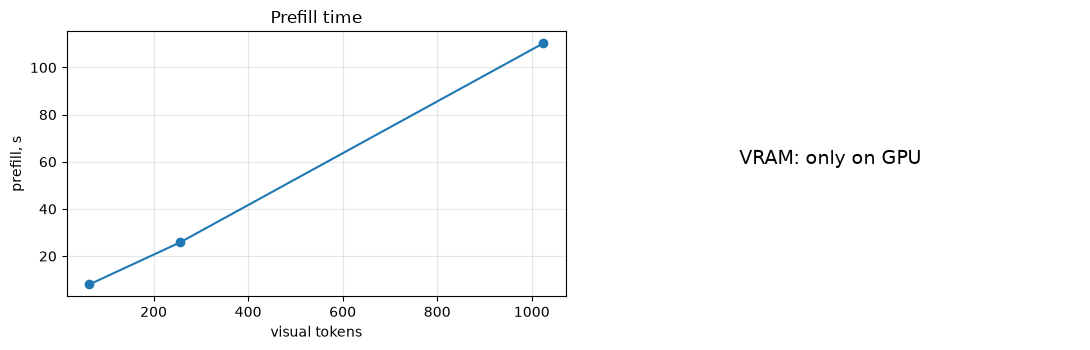

,max_tokens,visual tokens,"prefill, s","peak, GiB"
0,64,64,7.976,NaN
1,256,256,25.816,NaN
2,1024,1024,110.222,NaN


In [ ]:
def prefill_cost(max_tokens_list, side=1344):
    img = probe_image(64).resize((side, side))
    res = []
    for mt in max_tokens_list:
        inputs = build_inputs(proc, img, "Describe the image.", mt).to(model.device)
        if HAS_GPU:
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        with torch.inference_mode():
            model(**inputs)
        if HAS_GPU:
            torch.cuda.synchronize()
        res.append({"max_tokens": mt, "visual tokens": int(inputs["image_grid_thw"].prod(-1).sum() // 4),
                    "prefill, s": time.time() - t0,
                    "peak, GiB": torch.cuda.max_memory_allocated() / 2**30 if HAS_GPU else np.nan})
    return pd.DataFrame(res)

PREFILL = prefill_cost([64, 256, 1024] if FAST_DEV_RUN else [64, 256, 1024, 1764])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(PREFILL["visual tokens"], PREFILL["prefill, s"], "o-"); ax[0].set_xlabel("visual tokens"); ax[0].set_ylabel("prefill, s")
ax[0].set_title("Prefill time"); ax[0].grid(alpha=.3)
if HAS_GPU:
    ax[1].plot(PREFILL["visual tokens"], PREFILL["peak, GiB"], "o-", color="C3"); ax[1].set_title("Peak VRAM")
    ax[1].set_xlabel("visual tokens"); ax[1].set_ylabel("GiB"); ax[1].grid(alpha=.3)
else:
    ax[1].axis("off"); ax[1].text(0.5, 0.5, "VRAM: only on GPU", ha="center", fontsize=14)
plt.tight_layout(); plt.show()
PREFILL.round(3)

Документ A4 при 300 dpi (2480×3508) без ограничения дал бы около 8500 визуальных токенов. Даже на 4B-модели в 4 битах это секунды prefill и гигабайты активаций. Параметр «максимум визуальных токенов» поэтому — главный рычаг стоимости VLM: время prefill растёт с ним примерно линейно или быстрее, а качество OCR — только до некоторого предела (раздел 6).

### 2.3. NF4 своими руками

Возьмём настоящую матрицу весов одного слоя LLM прямо из файла safetensors: в памяти модели на GPU она уже квантована. Сравним три способа хранения блоками по 64 веса:

- равномерная INT4 с absmax-масштабом;
- NF4 — 16 квантилей нормального распределения, как в [QLoRA](https://arxiv.org/abs/2305.14314);
- NF4 с двойным квантованием масштабов.

Если доступен bitsandbytes (GPU), сверим нашу реализацию с библиотечной.

In [ ]:
from huggingface_hub import hf_hub_download
from safetensors import safe_open
from scipy.stats import norm, kurtosis

def load_original_tensor(model_id, name):
    try:
        idx = json.load(open(hf_hub_download(model_id, "model.safetensors.index.json")))
        shard = idx["weight_map"][name]
    except Exception:
        shard = "model.safetensors"
    with safe_open(hf_hub_download(model_id, shard), framework="pt") as f:
        return f.get_tensor(name).float()

W = load_original_tensor(MODEL_ID, "model.language_model.layers.10.mlp.down_proj.weight")
print("W:", tuple(W.shape), "std %.4f, excess kurtosis %.2f" % (W.std(), kurtosis(W.flatten().numpy()[::7])))

def nf4_levels():
    off = 0.9677083   # как в QLoRA/bitsandbytes: середина между 1-1/(2·15) и 1-1/(2·16)
    pos = norm.ppf(np.linspace(off, 0.5, 9)[:-1]).tolist()
    neg = (-norm.ppf(np.linspace(off, 0.5, 8)[:-1])).tolist()
    v = np.array(sorted(pos + [0.0] + neg))
    return torch.tensor(v / v.max(), dtype=torch.float32)

NF4 = nf4_levels()
INT4 = torch.linspace(-1, 1, 16)
print("NF4 levels:", np.round(NF4.numpy(), 4))

def blockwise_quant(w, levels, block=64, double_quant=False):
    x = w.flatten()
    x = x[: x.numel() // block * block].view(-1, block)
    absmax = x.abs().amax(1, keepdim=True)
    if double_quant:   # масштабы в 8 бит блоками по 256 (упрощённая схема)
        a = absmax.view(-1)
        a = a[: a.numel() // 256 * 256].view(-1, 256)
        m = a.mean(1, keepdim=True)
        s = (a - m).abs().amax(1, keepdim=True) / 127
        a_q = torch.round((a - m) / s).clamp(-127, 127) * s + m
        absmax = torch.cat([a_q.flatten(), absmax.view(-1)[a_q.numel():]]).view(-1, 1)
    xn = x / absmax
    idx = (xn.unsqueeze(-1) - levels).abs().argmin(-1)
    return (levels[idx] * absmax).flatten(), idx

ref = W.flatten()[: W.numel() // 64 * 64]
res = []
for name, lv, dq in [("INT4 absmax", INT4, False), ("NF4", NF4, False), ("NF4 + double quant", NF4, True)]:
    deq, idx = blockwise_quant(W, lv, double_quant=dq)
    err = deq - ref
    bits = 4 + (8 / 64 + 32 / (64 * 256) if dq else 32 / 64)
    res.append({"format": name, "bits/weight": round(bits, 3), "RMSE": err.pow(2).mean().sqrt().item(),
                "rel. error, %": 100 * err.norm().item() / ref.norm().item(),
                "levels used (entropy, bits)": float(-(np.bincount(idx.flatten().numpy(), minlength=16) / idx.numel() *
                                                       np.log2(np.bincount(idx.flatten().numpy(), minlength=16) / idx.numel() + 1e-12)).sum())})
Q = pd.DataFrame(res)

if HAS_GPU:
    import bitsandbytes.functional as bnbF
    w16 = W.to("cuda", torch.float16)
    qw, st = bnbF.quantize_4bit(w16, blocksize=64, quant_type="nf4")
    deq_bnb = bnbF.dequantize_4bit(qw, st).float().cpu().flatten()[: ref.numel()]
    ours = blockwise_quant(W, NF4)[0]
    print("bitsandbytes NF4 rel. error, %%: %.3f | расхождение с нашей реализацией: %.2e" %
          (100 * (deq_bnb - ref).norm() / ref.norm(), (deq_bnb - ours).abs().max()))
Q.round(4)

W: (2048, 6144) std 0.0304, excess kurtosis 1.69
NF4 levels: [-1.     -0.6962 -0.5251 -0.3949 -0.2844 -0.1848 -0.091   0.      0.0796
  0.1609  0.2461  0.3379  0.4407  0.5626  0.723   1.    ]


,format,bits/weight,RMSE,"rel. error, %","levels used (entropy, bits)"
0,INT4 absmax,4.500,0.0034,11.0761,3.4991
1,NF4,4.500,0.0029,9.5108,3.8299
2,NF4 + double quant,4.127,0.0029,9.5119,3.8299


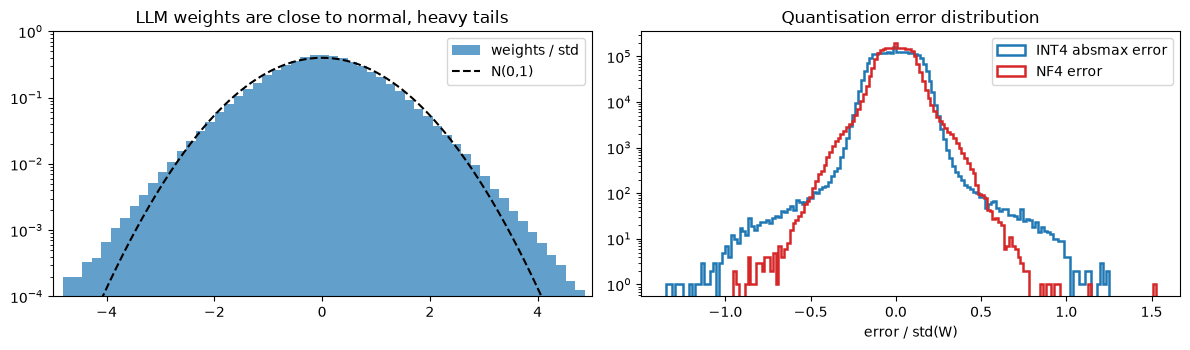

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
x = W.flatten().numpy()[::5]
ax[0].hist(x / x.std(), bins=200, density=True, alpha=.7, label="weights / std")
g = np.linspace(-5, 5, 400); ax[0].plot(g, norm.pdf(g), "k--", label="N(0,1)")
ax[0].set_xlim(-5, 5); ax[0].set_yscale("log"); ax[0].set_ylim(1e-4, 1); ax[0].legend(); ax[0].set_title("LLM weights are close to normal, heavy tails")
for name, lv, c in [("INT4 absmax", INT4, "C0"), ("NF4", NF4, "C3")]:
    d, _ = blockwise_quant(W, lv)
    ax[1].hist(((d - ref) / ref.std()).numpy()[::5], bins=150, histtype="step", lw=1.8, color=c, label=f"{name} error")
ax[1].set_yscale("log"); ax[1].set_xlabel("error / std(W)"); ax[1].legend(); ax[1].set_title("Quantisation error distribution")
plt.tight_layout(); plt.show()

Как читать результат:

- NF4 даёт меньшую ошибку, чем равномерная INT4, при той же памяти. У весов, близких к нормальным, большинство значений лежит около нуля, и NF4 ставит туда больше уровней.
- Энтропия использования уровней у NF4 ближе к 4 битам: все 16 кодов используются почти равномерно. У INT4 крайние коды почти пусты, то есть часть битов тратится впустую.
- Двойное квантование почти не меняет ошибку, но сокращает накладные расходы с 0.5 до примерно 0.127 бита на вес.
- Логарифмическая гистограмма показывает «тяжёлые хвосты»: выбросы больше 4σ. Именно они задают absmax блока и ухудшают точность остальных 63 весов. Поэтому блоки маленькие (64), а методы вроде [LLM.int8()](https://arxiv.org/abs/2208.07339) и [AWQ](https://arxiv.org/abs/2306.00978) обрабатывают выбросы отдельно.

## 3. Данные и инструменты оценки

Соберём общие утилиты:

- `ask` — вызов модели с кэшем ответов. Повторный запуск ячейки не тратит время на уже посчитанные примеры;
- `bootstrap_ci` — 95%-ный доверительный интервал среднего по бутстрепу. На выборках в десятки примеров разница в 5–10 п.п. часто лежит внутри шума, поэтому интервал печатается рядом с каждой метрикой;
- `RESULTS` — сводная таблица результатов для раздела 13.

In [ ]:
import requests, pyarrow.parquet as pq

CACHE = {}
RESULTS = []

def ask(img, prompt, key, max_new_tokens=16, max_tokens=MAX_VISUAL_TOKENS, system=None, m=None, p=None, mid=None):
    m, p, mid = m or model, p or proc, mid or MODEL_ID
    # для запроса без изображения бюджет токенов не важен: ключ не должен совпадать с запросом с картинкой
    k = (mid, key, prompt, max_tokens if img is not None else "blind", max_new_tokens, system)
    if k not in CACHE:
        CACHE[k] = generate(m, p, img, prompt, max_new_tokens, max_tokens, system)
    return CACHE[k]

def bootstrap_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return (np.nan, np.nan, np.nan)
    r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n_boot, len(x)))].mean(1)
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

def fmt(x, pct=True):
    m, lo, hi = bootstrap_ci(x)
    k = 100 if pct else 1
    return f"{k*m:.1f} [{k*lo:.1f}; {k*hi:.1f}]"

def record(task, metric, values, model_id=None, pct=True):
    m, lo, hi = bootstrap_ci(values)
    k = 100 if pct else 1
    RESULTS.append({"model": (model_id or MODEL_ID).split("/")[-1], "task": task, "metric": metric,
                    "value": round(k * m, 1), "ci95": f"[{k*lo:.1f}; {k*hi:.1f}]", "n": len(values)})

def show_images(items, ncols=4, size=3.2):
    nrows = math.ceil(len(items) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.95))
    for ax in np.array(axes).flatten():
        ax.axis("off")
    for ax, (img, title) in zip(np.array(axes).flatten(), items):
        ax.imshow(img); ax.set_title(title, fontsize=8.5, loc="left")
    plt.tight_layout(); plt.show()

def hf_parquet(repo_ids, filename):
    for rid in repo_ids:
        try:
            return pq.read_table(hf_hub_download(rid, filename, repo_type="dataset")).to_pandas()
        except Exception as e:
            last = e
    raise last

def to_pil(d):
    return Image.open(io.BytesIO(d["bytes"])).convert("RGB")

FONT = font_manager.findfont("DejaVu Sans")
FONT_MONO = font_manager.findfont("DejaVu Sans Mono")
def font(size, mono=False):
    return ImageFont.truetype(FONT_MONO if mono else FONT, size)
print("Шрифты:", FONT, FONT_MONO)

Шрифты: /home/user/cvtest/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf /home/user/cvtest/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSansMono.ttf


In [ ]:
# POPE (adversarial): 500 изображений COCO × 6 вопросов, половина ответов "yes"
pope = hf_parquet(["lmms-lab/POPE", "lmms-lab-encoder/POPE"], "Full/adversarial-00000-of-00001.parquet")
# в части вопросов датасета опечатка «imange», поэтому шаблон не привязан к слову image целиком
pope["object"] = pope.question.str.extract(r"Is there an? (.+?) in the ima")[0]
assert pope.object.notna().all(), pope[pope.object.isna()].question.head()
print("POPE:", pope.shape, pope.answer.value_counts().to_dict())

# Flickr8k test: 1000 изображений, по 5 подписей
f8k = hf_parquet(["jxie/flickr8k"], "data/test-00000-of-00001-42a2661d12c73e48.parquet")
f8k_caps = [[f8k[f"caption_{j}"][i].strip() for j in range(5)] for i in range(len(f8k))]
print("Flickr8k:", len(f8k), "изображений")

# TextVQA validation через datasets-server: читаем только нужные строки, а не 900 МБ parquet
def textvqa_rows(offset=0, length=100):
    for name in ["lmms-lab/textvqa", "lmms-lab-encoder/textvqa"]:
        url = f"https://datasets-server.huggingface.co/rows?dataset={name}&config=default&split=validation&offset={offset}&length={length}"
        try:
            r = requests.get(url, timeout=60)
            if r.ok and "rows" in r.json():
                return [x["row"] for x in r.json()["rows"]]
        except Exception as e:
            print("datasets-server:", e)
    return []

def fetch_image(url):
    r = requests.get(url, timeout=60); r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

tvqa_meta = textvqa_rows(0, 100)
print("TextVQA:", len(tvqa_meta), "строк")

POPE: (3000, 8) {'yes': 1500, 'no': 1500}


Flickr8k: 1000 изображений


TextVQA: 100 строк


## 4. Captioning: метрики и их ограничения

Сгенерируем подписи двумя промптами: короткая подпись в одно предложение и подробное описание. Сравним три метрики:

- CIDEr-D ([Vedantam et al.](https://arxiv.org/abs/1411.5726)) — TF-IDF-взвешенное совпадение n-грамм (n = 1…4) с эталонными подписями. IDF считаем по всем 5000 подписям тестовой части Flickr8k;
- CLIPScore ([Hessel et al.](https://arxiv.org/abs/2104.08718)) — $2.5\cdot\max(\cos(E_I, E_T), 0)$ по модели CLIP ViT-B/32 с префиксом «A photo depicts». Эталоны не нужны;
- длина подписи в словах.

Для ориентира посчитаем те же метрики для человеческой подписи: первая из 5 подписей сравнивается с остальными четырьмя. Подписи модели сравниваются с теми же четырьмя эталонами.

In [ ]:
from collections import Counter, defaultdict

def tok(s):
    return re.findall(r"[a-z0-9]+", s.lower())

def ngrams(words, n):
    return Counter(tuple(words[i:i + n]) for i in range(len(words) - n + 1))

class CiderD:
    """CIDEr-D: IDF по корпусу эталонов, гауссов штраф за длину (sigma=6), клиппинг счётчиков, множитель 10."""
    def __init__(self, all_refs):
        self.df = [Counter() for _ in range(4)]
        for refs in all_refs:
            for n in range(4):
                seen = set()
                for r in refs:
                    seen |= set(ngrams(tok(r), n + 1))
                for g in seen:
                    self.df[n][g] += 1
        self.log_n = math.log(len(all_refs))

    def _vec(self, words, n):
        c = ngrams(words, n + 1)
        return {g: tf * (self.log_n - math.log(max(1.0, self.df[n][g]))) for g, tf in c.items()}

    def score(self, cand, refs, sigma=6.0):
        cw = tok(cand)
        total = 0.0
        for n in range(4):
            vc = self._vec(cw, n)
            nc = math.sqrt(sum(v * v for v in vc.values())) or 1e-9
            s = 0.0
            for r in refs:
                rw = tok(r)
                vr = self._vec(rw, n)
                nr = math.sqrt(sum(v * v for v in vr.values())) or 1e-9
                dot = sum(min(vc[g], vr[g]) * vr[g] for g in vc if g in vr)
                s += dot / (nc * nr) * math.exp(-((len(cw) - len(rw)) ** 2) / (2 * sigma ** 2))
            total += s / len(refs)
        return 10.0 * total / 4

cider = CiderD(f8k_caps)

from transformers import CLIPModel, CLIPProcessor
clip_m = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_p = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def _as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output

@torch.no_grad()
def clipscore(img, caption):
    ii = clip_p(images=img, return_tensors="pt").to(DEVICE)
    tt = clip_p(text=["A photo depicts " + caption], return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
    fi = torch.nn.functional.normalize(_as_tensor(clip_m.get_image_features(**ii)), dim=-1)
    ft = torch.nn.functional.normalize(_as_tensor(clip_m.get_text_features(**tt)), dim=-1)
    return 2.5 * max((fi * ft).sum().item(), 0.0)

In [ ]:
N_CAP = n_(40, 3)
cap_idx = list(range(0, 1000, 1000 // N_CAP))[:N_CAP]
SHORT = "Write a one-sentence caption for this image."
DETAILED = "Describe this image in detail."
cap_rows = []
for i in cap_idx:
    img = to_pil(f8k.image[i])
    refs = f8k_caps[i][1:]
    s = ask(img, SHORT, f"f8k{i}", max_new_tokens=40, max_tokens=512)["text"]
    d = ask(img, DETAILED, f"f8k{i}", max_new_tokens=n_(160, 64), max_tokens=512)["text"]
    for kind, c in [("human (ref #0)", f8k_caps[i][0]), ("model, short", s), ("model, detailed", d)]:
        cap_rows.append({"i": i, "kind": kind, "caption": c, "CIDEr-D": cider.score(c, refs),
                         "CLIPScore": clipscore(img, c), "words": len(tok(c))})
CAP = pd.DataFrame(cap_rows)
summary = CAP.groupby("kind")[["CIDEr-D", "CLIPScore", "words"]].mean().round(3)
for kind in ["model, short", "model, detailed"]:
    record("captioning (Flickr8k)", f"CIDEr-D, {kind}", CAP[CAP.kind == kind]["CIDEr-D"], pct=False)
    record("captioning (Flickr8k)", f"CLIPScore, {kind}", CAP[CAP.kind == kind]["CLIPScore"], pct=False)
summary

,CIDEr-D,CLIPScore,words
kind,,,
human (ref #0),0.800,0.768,9.333
"model, detailed",0.000,0.810,55.000
"model, short",0.192,0.871,23.000


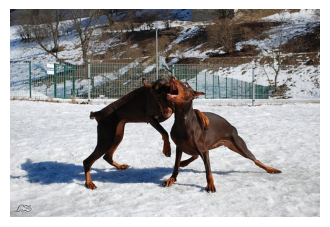

[human (ref #0)] CIDEr-D=1.21 CLIPScore=0.70
  The dogs are in the snow in front of a fence .
[model, short] CIDEr-D=0.57 CLIPScore=0.99
  Two Doberman dogs are playfully wrestling in the snow on a sunny day.
[model, detailed] CIDEr-D=0.00 CLIPScore=0.95
  This is a dynamic, outdoor photograph capturing two Doberman Pinschers in a fierce, playful fight on a snowy field. The scene is set in a winter landscape, with a snow-covered ground, a green metal fence, and bare trees in the background.

The two dogs are the central focus, both with their bodies in
----------------------------------------------------------------------------------------------------


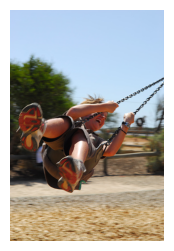

[human (ref #0)] CIDEr-D=0.51 CLIPScore=0.76
  A lady is swinging and smiling .
[model, short] CIDEr-D=0.01 CLIPScore=0.73
  A young boy with spiky hair is screaming with joy as he swings wildly on a chain swing under a clear blue sky.
[model, detailed] CIDEr-D=0.00 CLIPScore=0.76
  This is a dynamic, action-oriented photograph capturing a young boy in mid-swing at a playground. The image is taken from a low angle, emphasizing the motion and the boy's energetic posture.

The central subject is a young boy with short, spiky blonde hair, who is swinging on a swing set. He
----------------------------------------------------------------------------------------------------


In [ ]:
for i in cap_idx[:2]:
    sub = CAP[CAP.i == i].set_index("kind")
    plt.figure(figsize=(4, 3)); plt.imshow(to_pil(f8k.image[i])); plt.axis("off"); plt.show()
    for kind in sub.index:
        print(f"[{kind}] CIDEr-D={sub.loc[kind,'CIDEr-D']:.2f} CLIPScore={sub.loc[kind,'CLIPScore']:.2f}\n  {sub.loc[kind,'caption'][:400]}")
    print("-" * 100)

Чему учит этот эксперимент:

- Подробное описание почти всегда получает низкий CIDEr-D, хотя содержит больше верной информации. CIDEr сравнивает с короткими эталонами Flickr8k и штрафует расхождение длины. Метрика измеряет похожесть на стиль эталонов, а не полезность описания.
- CLIPScore не нуждается в эталонах, но CLIP видит только первые 77 токенов текста. Хвост длинного описания, включая возможные галлюцинации, просто не оценивается. Кроме того, CLIP сам плохо различает порядок слов и отношения (лекция 5).
- Короткие подписи модели по CLIPScore не хуже человеческих, а в нашем прогоне даже выше, но по CIDEr-D заметно ниже: модель выбирает другие слова и другую детализацию («two Doberman dogs are playfully wrestling» вместо «the dogs are in the snow»). CIDEr-D дополнительно штрафует разницу длины гауссовым множителем, поэтому описание из 50+ слов получает почти ноль.

Вывод для практики: для captioning нужна связка метрик (n-граммная, эмбеддинговая и проверка галлюцинаций), а для подробных описаний — оценка фактов, а не n-грамм (разделы 5 и 10).

## 5. Галлюцинации: POPE и слепой тест

[POPE](https://arxiv.org/abs/2305.10355) задаёт вопросы «Is there a {object} in the image?». Половина объектов присутствует на изображении, половина отсутствует. В adversarial-разбиении отсутствующие объекты выбираются среди тех, что чаще всего встречаются вместе с присутствующими: для кухни — «fork», для улицы — «car». Это проверяет, опирается ли модель на изображение или на статистику совместной встречаемости.

Метрики: accuracy, precision, recall и F1 по классу «yes», а также доля ответов «yes». Сильный перекос yes-ratio выше 50% — признак склонности соглашаться.

Слепой тест: те же вопросы без изображения. Если без картинки точность заметно выше 50%, часть вопросов решается языковыми априорными знаниями. Это важный контроль для любого бенчмарка ([MMStar](https://arxiv.org/abs/2403.20330)).

In [ ]:
def yes_no(text):
    t = text.strip().lower()
    if t.startswith("yes"):
        return "yes"
    if t.startswith("no"):
        return "no"
    return "yes" if re.search(r"\byes\b", t) else "no"

def binary_metrics(pred, gold):
    pred, gold = np.array(pred), np.array(gold)
    tp = ((pred == "yes") & (gold == "yes")).sum(); fp = ((pred == "yes") & (gold == "no")).sum()
    fn = ((pred == "no") & (gold == "yes")).sum()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(acc=(pred == gold).mean(), precision=prec, recall=rec, F1=2 * prec * rec / max(prec + rec, 1e-9),
                yes_ratio=(pred == "yes").mean())

N_POPE_IMG = n_(100, 4)
pope_imgs = pope.image_source.drop_duplicates().iloc[:N_POPE_IMG].tolist()
pope_sub = pope[pope.image_source.isin(pope_imgs)].reset_index(drop=True)
pope_pil = {s: to_pil(pope_sub[pope_sub.image_source == s].image.iloc[0]) for s in pope_imgs}

def run_pope(df, m=None, p=None, mid=None, blind_too=True):
    preds, blind = [], []
    for _, r in df.iterrows():
        q = r.question + " Answer yes or no."
        preds.append(yes_no(ask(pope_pil[r.image_source], q, f"pope{r.question_id}", 3, 512, m=m, p=p, mid=mid)["text"]))
        if blind_too:
            blind.append(yes_no(ask(None, q, f"pope{r.question_id}", 3, m=m, p=p, mid=mid)["text"]))
    return preds, blind

preds, blind = run_pope(pope_sub)
pope_sub["pred"], pope_sub["blind"] = preds, blind
POPE_M = pd.DataFrame({"with image": binary_metrics(preds, pope_sub.answer), "blind (no image)": binary_metrics(blind, pope_sub.answer)}).T
record("POPE adversarial", "accuracy", (pope_sub.pred == pope_sub.answer).astype(float))
record("POPE adversarial", "accuracy, blind", (pope_sub.blind == pope_sub.answer).astype(float))
print("n =", len(pope_sub), "| accuracy с изображением:", fmt((pope_sub.pred == pope_sub.answer).astype(float)))
POPE_M.round(3)

n = 24 | accuracy с изображением: 79.2 [62.5; 95.8]


,acc,precision,recall,F1,yes_ratio
with image,0.792,0.818,0.750,0.783,0.458
blind (no image),0.458,0.478,0.917,0.629,0.958


Как читать таблицу. В сохранённом CPU-прогоне (24 вопроса) Qwen3-VL-2B с изображением не склонна соглашаться: доля «yes» около 46% при 50% в данных. Без изображения та же модель отвечает «yes» почти всегда (96%) — это и есть языковой приор «соглашаться с вопросом», от которого защищает только визуальная информация. Accuracy в слепом режиме около 50%, как и должно быть на сбалансированной выборке; заметно больше 50% означало бы утечку ответа через текст вопроса.

Ошибок: 5 | из них ложных 'yes' (галлюцинаций): 2


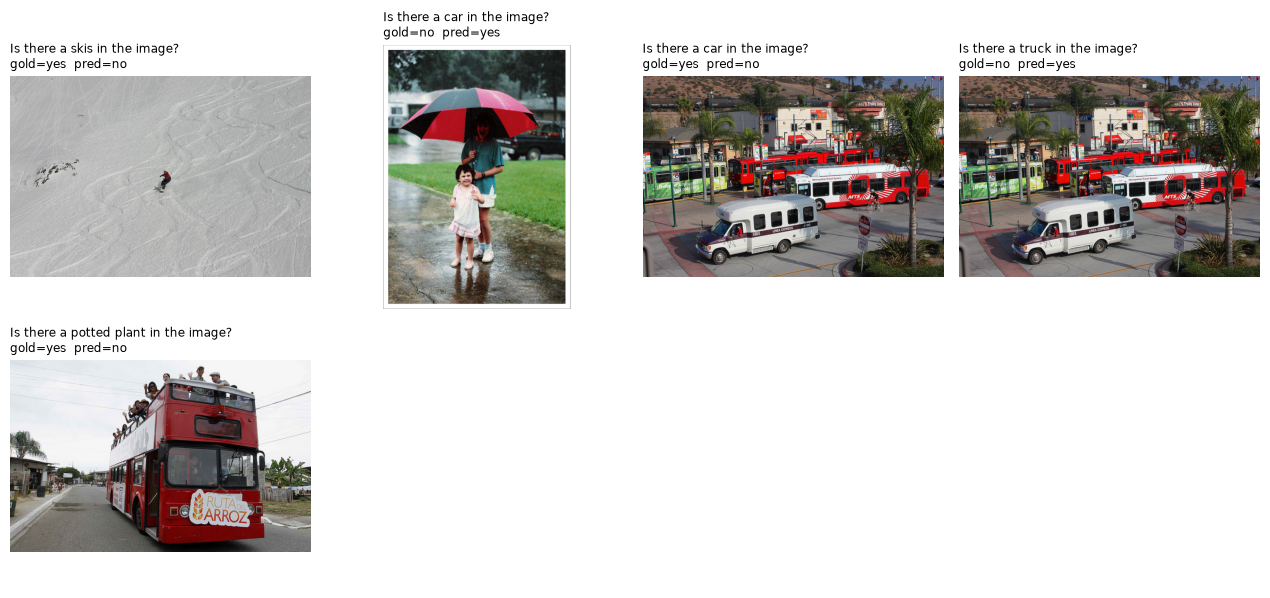

In [ ]:
errs = pope_sub[pope_sub.pred != pope_sub.answer]
print("Ошибок:", len(errs), "| из них ложных 'yes' (галлюцинаций):", int((errs.pred == "yes").sum()))
show_images([(pope_pil[r.image_source], f"{r.question}\ngold={r.answer}  pred={r.pred}") for _, r in errs.head(8).iterrows()], ncols=4)

### Галлюцинации в свободном описании

Вопрос «да/нет» — удобный, но узкий тест. В свободном описании модель сама решает, что упомянуть. Повторим идею CHAIR ([Rohrbach et al.](https://arxiv.org/abs/1809.02156)) в упрощённом виде. Для каждого изображения POPE известны 3 присутствующих и 3 отсутствующих (adversarial) объекта. Попросим подробное описание и посчитаем:

- recall — долю присутствующих объектов, которые упомянуты;
- долю описаний, где упомянут хотя бы один отсутствующий объект (аналог CHAIR$_s$).

Сопоставление идёт по словам с простыми формами множественного числа, поэтому это нижняя оценка: синонимы вроде «guy» вместо «person» не засчитываются.

In [ ]:
def mentions(text, obj):
    t = " " + " ".join(tok(text)) + " "
    forms = {obj, obj + "s", obj + "es", obj[:-1] + "ies" if obj.endswith("y") else obj}
    if obj == "person":
        forms |= {"people", "man", "men", "woman", "women", "boy", "girl", "child", "children", "player", "persons"}
    return any(f" {f} " in t for f in forms)

N_CHAIR = n_(40, 3)
ch_rows = []
for s in pope_imgs[:N_CHAIR]:
    sub = pope_sub[pope_sub.image_source == s]
    desc = ask(pope_pil[s], DETAILED, f"chair_{s}", max_new_tokens=n_(200, 80), max_tokens=512)["text"]
    pres = sub[sub.answer == "yes"].object.tolist(); absn = sub[sub.answer == "no"].object.tolist()
    ch_rows.append({"image": s, "recall present": np.mean([mentions(desc, o) for o in pres]),
                    "mentions absent": any(mentions(desc, o) for o in absn),
                    "absent mentioned": [o for o in absn if mentions(desc, o)], "words": len(tok(desc)), "desc": desc})
CH = pd.DataFrame(ch_rows)
print("recall присутствующих объектов:", fmt(CH["recall present"]))
print("доля описаний с отсутствующим объектом (CHAIR_s-подобная):", fmt(CH["mentions absent"].astype(float)))
record("caption hallucination (POPE images)", "share of captions with absent object", CH["mentions absent"].astype(float))
CH[["image", "recall present", "absent mentioned", "words"]]

recall присутствующих объектов: 22.2 [0.0; 66.7]
доля описаний с отсутствующим объектом (CHAIR_s-подобная): 0.0 [0.0; 0.0]


,image,recall present,absent mentioned,words
0,COCO_val2014_000000310196,0.000000,[],67
1,COCO_val2014_000000210789,0.666667,[],69
2,COCO_val2014_000000429109,0.000000,[],68


Если в описании упомянут «отсутствующий» объект, прочитайте этот фрагмент: иногда это настоящая галлюцинация, иногда — отрицание («there is no car») или ошибка разметки COCO. Автоматические метрики галлюцинаций нужно выборочно проверять глазами — это общее правило.

В литературе описана такая картина: модель уверенно отвечает «no» на прямой вопрос об отсутствующем объекте, но в длинном описании может «дорисовать» типичный для сцены предмет, потому что генерация длинного текста опирается на языковую модель сильнее, чем короткий ответ ([CHAIR](https://arxiv.org/abs/1809.02156)). В сохранённом CPU-прогоне (3 описания) отсутствующих объектов не упомянуто, зато recall присутствующих низкий: модель описывает сцену общими словами и не называет многие объекты COCO. На GPU выборка 40 изображений; проверьте, останется ли доля описаний с галлюцинациями нулевой.

## 6. VQA с OCR: TextVQA и разрешение

В [TextVQA](https://arxiv.org/abs/1904.08920) на каждый вопрос есть 10 ответов людей. Стандартная VQA accuracy ([Antol et al.](https://arxiv.org/abs/1505.00468)):
$$
\mathrm{Acc}(a)=\min\Big(\frac{\#\{\text{людей, давших ответ } a\}}{3},\,1\Big),
$$
то есть ответ засчитывается полностью, если его дали хотя бы трое из десяти. Официальная формула ещё усредняет её по 10 подмножествам из 9 ответов; мы используем упрощённый вариант. Для сравнения посчитаем ANLS ([DocVQA](https://arxiv.org/abs/2007.00398)): нормированное сходство по расстоянию Левенштейна с порогом 0.5. ANLS частично засчитывает ответ с опечаткой.

Прогоним одни и те же вопросы при разном бюджете визуальных токенов и без изображения.

In [ ]:
NUM = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
def norm_ans(s):
    s = s.lower().strip().rstrip(".")
    s = re.sub(r"[\"'`,!?;:()]", "", s)
    words = [NUM.get(w, w) for w in s.split() if w not in {"a", "an", "the"}]
    return " ".join(words)

def vqa_acc(pred, answers):
    p = norm_ans(pred)
    return min(sum(norm_ans(a) == p for a in answers) / 3.0, 1.0)

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def anls(pred, answers, tau=0.5):
    best = 0.0
    for a in answers:
        p, g = norm_ans(pred), norm_ans(a)
        nl = levenshtein(p, g) / max(len(p), len(g), 1)
        best = max(best, 1 - nl if nl < tau else 0.0)
    return best

VQA_SUFFIX = "\nAnswer the question using a single word or phrase."
N_TVQA = n_(100, 4)
TOKEN_BUDGETS = [256, 1024] if FAST_DEV_RUN else [256, 1024, 2048]
TVQA_IMG = {}
def run_tvqa(budgets, m=None, p=None, mid=None, blind_too=True):
    rows = []
    for r in tvqa_meta[:N_TVQA]:
        if r["question_id"] not in TVQA_IMG:
            try:
                TVQA_IMG[r["question_id"]] = fetch_image(r["image"]["src"])
            except Exception as e:
                print("пропуск:", e); continue
        img = TVQA_IMG[r["question_id"]]
        q = r["question"] + VQA_SUFFIX
        for mt in list(budgets) + (["blind"] if blind_too else []):
            out = ask(None if mt == "blind" else img, q, f"tvqa{r['question_id']}", 16,
                      MAX_VISUAL_TOKENS if mt == "blind" else mt, m=m, p=p, mid=mid)
            rows.append({"qid": r["question_id"], "budget": str(mt), "question": r["question"], "pred": out["text"],
                         "answers": r["answers"], "acc": vqa_acc(out["text"], r["answers"]), "anls": anls(out["text"], r["answers"]),
                         "visual tokens": out["n_visual"], "seconds": out["seconds"], "img": img})
    return pd.DataFrame(rows)

TV = run_tvqa(TOKEN_BUDGETS)
TV_SUM = TV.groupby("budget", sort=False).agg(vqa_acc=("acc", "mean"), anls=("anls", "mean"),
                                               visual_tokens=("visual tokens", "mean"), seconds=("seconds", "mean"), n=("acc", "size"))
for b, g in TV.groupby("budget", sort=False):
    record("TextVQA", f"VQA acc, budget={b}", g.acc)
TV_SUM.round(3)

,vqa_acc,anls,visual_tokens,seconds,n
budget,,,,,
256,0.75,0.982,245.75,24.662,4
1024,0.75,0.982,728.00,71.380,4
blind,0.00,0.000,0.00,2.603,4


In [ ]:
best_b = str(TOKEN_BUDGETS[-1]); low_b = str(TOKEN_BUDGETS[0])
piv = TV.pivot_table(index="qid", columns="budget", values="acc", aggfunc="first")
gain = piv[(piv[best_b] > piv[low_b])].index[:4]
items = []
for qid in gain:
    sub = TV[(TV.qid == qid)].set_index("budget")
    items.append((sub.loc[best_b, "img"], f"Q: {sub.loc[best_b,'question'][:60]}\n{low_b} tok: {sub.loc[low_b,'pred'][:30]}\n{best_b} tok: {sub.loc[best_b,'pred'][:30]}\ngold: {Counter(sub.loc[best_b,'answers']).most_common(1)[0][0]}"))
if items:
    show_images(items, ncols=4, size=3.6)
else:
    print("В этой выборке нет вопросов, где большее разрешение исправило ответ.")

В этой выборке нет вопросов, где большее разрешение исправило ответ.


В сохранённом CPU-прогоне всего 4 вопроса: при 256 и 1024 токенах точность одинакова (VQA accuracy 0.75, ANLS 0.98), а время ответа выросло с 25 до 71 с. Без изображения модель не ответила ни на один вопрос. На такой выборке различий по разрешению не видно; на GPU при 100 вопросах они появляются там, где текст мелкий.

Что обычно наблюдается на больших выборках:

- При 256 визуальных токенах (один токен на 32×32 пикселя изображения около 512×512) мелкий текст сливается, и точность заметно ниже. С ростом бюджета она растёт, затем выходит на плато, а время продолжает расти.
- Слепой режим даёт ненулевую точность. Часть вопросов («what brand is this phone?») угадывается по частотным ответам. Такие вопросы завышают оценку «понимания изображения».
- ANLS выше VQA accuracy: она засчитывает частично верные ответы вроде «coca cola» против «coca-cola». Это же и минус: «2015» против «2016» получает 0.75.

### Синтетический OCR-тест: размер шрифта × разрешение

На реальных фото много факторов сразу: ракурс, освещение, шрифт. Синтетика позволяет менять один фактор. Нарисуем на листе 1280×960 случайный код из 8 символов разного размера и попросим модель его прочитать. Метрика — CER (character error rate), расстояние Левенштейна, делённое на длину кода.

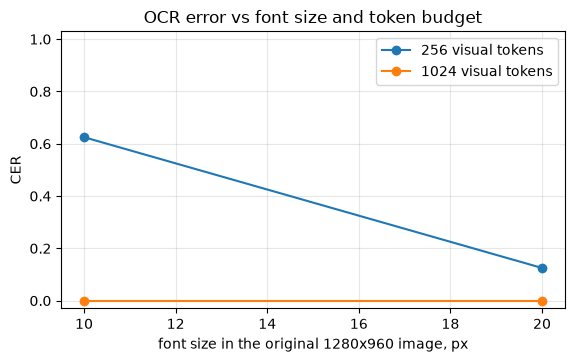

budget,256,1024
font px,,
10,0.62,0.0
20,0.12,0.0


In [ ]:
ALPH = "ABCDEFGHJKLMNPQRSTUVWXYZ23456789"   # без 0/O и 1/I, чтобы ошибка была ошибкой чтения, а не неоднозначностью
def code_image(code, size, seed=0):
    r = random.Random(seed)
    img = Image.new("RGB", (1280, 960), (250, 250, 245)); d = ImageDraw.Draw(img)
    for _ in range(14):   # фоновые слова-отвлекатели
        d.text((r.randint(0, 1100), r.randint(0, 900)), r.choice(["invoice", "total", "paid", "ref", "date", "qty"]), fill=(150, 150, 150), font=font(16))
    f = font(size, mono=True)
    x, y = r.randint(40, 600), r.randint(100, 800)
    d.text((x - 2, y - size - 6), "CODE:", fill=(60, 60, 60), font=font(max(10, size // 2)))
    d.text((x, y), code, fill=(10, 10, 10), font=f)
    return img

FONT_SIZES = [10, 20] if FAST_DEV_RUN else [8, 10, 12, 16, 20, 28]
OCR_BUDGETS = [256, 1024] if FAST_DEV_RUN else [256, 1024, 2048]
N_CODES = n_(5, 1)
def run_ocr(budgets, m=None, p=None, mid=None):
    rows = []
    for k in range(N_CODES):
        rng = random.Random(100 + k)
        code = "".join(rng.choice(ALPH) for _ in range(8))
        for fs in FONT_SIZES:
            img = code_image(code, fs, seed=k)
            for mt in budgets:
                out = ask(img, "Read the code printed after 'CODE:'. Answer with the code only.", f"code{k}_{fs}", 12, mt, m=m, p=p, mid=mid)
                pred = re.sub(r"[^A-Z0-9]", "", out["text"].upper())
                rows.append({"code": code, "font px": fs, "budget": mt, "pred": pred,
                             "CER": min(1.0, levenshtein(pred, code) / len(code)), "exact": float(pred == code)})
    return pd.DataFrame(rows)

OCR = run_ocr(OCR_BUDGETS)
piv = OCR.pivot_table(index="font px", columns="budget", values="CER", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for b in piv.columns:
    ax.plot(piv.index, piv[b], "o-", label=f"{b} visual tokens")
ax.set_xlabel("font size in the original 1280x960 image, px"); ax.set_ylabel("CER"); ax.set_ylim(-0.03, 1.03)
ax.legend(); ax.grid(alpha=.3); ax.set_title("OCR error vs font size and token budget"); plt.show()
record("synthetic OCR", f"exact match, {OCR_BUDGETS[-1]} tokens", OCR[OCR.budget == OCR_BUDGETS[-1]].exact)
record("synthetic OCR", f"exact match, {OCR_BUDGETS[0]} tokens", OCR[OCR.budget == OCR_BUDGETS[0]].exact)
piv.round(2)

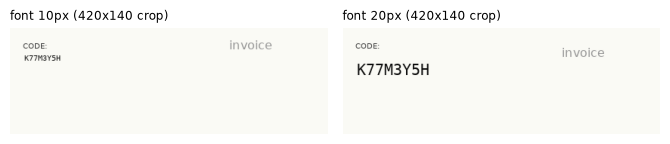

In [ ]:
def crop_code(img, w=420, h=140):
    """Вырезает окно фиксированного размера вокруг кода (тёмные пиксели), чтобы масштаб шрифтов был сравним."""
    ys, xs = np.where(np.asarray(img.convert("L")) < 80)
    x0, y0 = max(xs.min() - 20, 0), max(ys.min() - 20, 0)
    return img.crop((x0, y0, x0 + w, y0 + h))

shown = FONT_SIZES[:4]
show_images([(crop_code(code_image(OCR.code.iloc[0], fs, 0)), f"font {fs}px (420x140 crop)") for fs in shown], ncols=len(shown), size=3.4)

Результат сохранённого прогона (один код, CPU): при 256 токенах CER 0.62 для шрифта 10 px и 0.12 (одна ошибка из 8 символов) для 20 px; при 1024 токенах оба кода прочитаны без ошибок.

При бюджете 256 токенов лист 1280×960 сжимается примерно до 576×416 пикселей, то есть в 2.2 раза по каждой стороне. Шрифт 10 px превращается примерно в 4.5 px, и символы становятся неразличимы. Отсюда практическое правило: высота символа после ресайза должна быть не меньше примерно 8–10 пикселей. Отсюда же видно, зачем VLM для документов нужны тайлинг и динамическое разрешение (теоретическая часть, раздел 4).

## 7. Structured extraction: чек → JSON

Частая прикладная задача: извлечь из изображения поля по схеме. Сгенерируем чеки с известной истиной и попросим JSON заданной структуры. В чеке дата напечатана как ДД.ММ.ГГГГ, а в JSON требуется ГГГГ-ММ-ДД. Так проверяется не только чтение, но и следование формату.

Метрики на уровне полей — так оценивают реальные системы извлечения:

- доля валидного JSON;
- точное совпадение `store`, `date`, `total`;
- precision, recall и F1 по позициям чека: позиция засчитывается, если совпали название, количество и цена;
- арифметическая согласованность: равна ли сумма $\sum \text{qty}\cdot\text{price}$ в ответе полю `total` в ответе. Это проверка без эталона, её можно делать и в продакшене.

Условия: чистый скан и «фото» — поворот на 3°, размытие, шум и неравномерная яркость. На GPU добавляется низкий бюджет визуальных токенов.

In [ ]:
STORES = ["GREEN MARKET", "CITY PHARMACY", "BOOK CORNER", "CAFE AURORA", "TECH POINT", "NORTH BAKERY"]
GOODS = [("Milk 1L", 1.29), ("Bread", 0.99), ("Coffee beans", 7.49), ("Apples 1kg", 2.35), ("Notebook A5", 3.10),
         ("USB cable", 5.99), ("Green tea", 2.80), ("Cheese", 4.65), ("Pasta", 1.45), ("Orange juice", 2.99),
         ("Batteries AA", 4.20), ("Chocolate", 1.75), ("Yogurt", 0.85), ("Rice 1kg", 1.95)]

def make_receipt(seed):
    r = random.Random(seed)
    items = [{"name": n, "qty": r.randint(1, 3), "price": p} for n, p in r.sample(GOODS, r.randint(3, 6))]
    total = round(sum(i["qty"] * i["price"] for i in items), 2)
    y, mo, d = r.randint(2023, 2026), r.randint(1, 12), r.randint(1, 28)
    gold = {"store": r.choice(STORES), "date": f"{y:04d}-{mo:02d}-{d:02d}", "items": items, "total": total}
    W, H = 620, 260 + 44 * len(items)
    img = Image.new("RGB", (W, H), (252, 252, 248)); dr = ImageDraw.Draw(img)
    f, fb = font(22, mono=True), font(28, mono=True)
    dr.text((W // 2, 30), gold["store"], fill="black", font=fb, anchor="mt")
    dr.text((30, 80), f"Date: {d:02d}.{mo:02d}.{y}", fill="black", font=f)
    dr.text((30, 110), f"Receipt #{r.randint(1000, 9999)}   Cashier {r.randint(1, 9)}", fill=(70, 70, 70), font=font(18, mono=True))
    yy = 150
    for it in items:
        dr.text((30, yy), f"{it['name']:<14}{it['qty']} x {it['price']:.2f}", fill="black", font=f)
        dr.text((W - 30, yy), f"{it['qty'] * it['price']:.2f}", fill="black", font=f, anchor="ra"); yy += 44
    dr.line((30, yy + 5, W - 30, yy + 5), fill="black", width=2)
    dr.text((30, yy + 20), "TOTAL", fill="black", font=fb); dr.text((W - 30, yy + 20), f"{total:.2f}", fill="black", font=fb, anchor="ra")
    return img, gold

def photo_like(img, seed=0):
    r = np.random.default_rng(seed)
    im = img.rotate(3, expand=True, fillcolor=(120, 120, 120), resample=Image.BICUBIC).filter(ImageFilter.GaussianBlur(1.2))
    a = np.asarray(im).astype(np.float32)
    grad = np.linspace(0.75, 1.05, a.shape[1])[None, :, None]
    a = np.clip(a * grad + r.normal(0, 10, a.shape), 0, 255).astype(np.uint8)
    return Image.fromarray(a)

EXTRACT_PROMPT = ("Extract the receipt as JSON with keys: store (string), date (YYYY-MM-DD), "
                  "items (list of objects with name, qty as integer, price as unit price number), total (number). "
                  "Output only compact JSON on a single line, without markdown.")

def parse_json(text):
    t = re.sub(r"```(?:json)?", "", text)
    m = re.search(r"\{.*\}", t, flags=re.S)
    if not m:
        return None
    try:
        return json.loads(m.group(0))
    except Exception:
        return None

def _num(x):
    try:
        return float(str(x).replace(",", ".").replace("$", ""))
    except Exception:
        return None

def score_receipt(pred, gold):
    out = {"valid_json": pred is not None}
    if pred is None:
        return {**out, "store": 0.0, "date": 0.0, "total": 0.0, "item_P": 0.0, "item_R": 0.0, "item_F1": 0.0, "consistent": 0.0}
    out["store"] = float(str(pred.get("store", "")).strip().upper() == gold["store"])
    out["date"] = float(str(pred.get("date", "")).strip() == gold["date"])
    t = _num(pred.get("total")); out["total"] = float(t is not None and abs(t - gold["total"]) < 0.005)
    key = lambda it: (str(it.get("name", "")).strip().lower(), int(_num(it.get("qty")) or 0), round(_num(it.get("price")) or -1, 2))
    items = pred.get("items") if isinstance(pred.get("items"), list) else []
    pk = Counter(key(i) for i in items if isinstance(i, dict))
    gk = Counter((i["name"].lower(), i["qty"], round(i["price"], 2)) for i in gold["items"])
    tp = sum((pk & gk).values())
    P = tp / max(sum(pk.values()), 1); R = tp / max(sum(gk.values()), 1)
    out.update(item_P=P, item_R=R, item_F1=2 * P * R / max(P + R, 1e-9))
    s = sum((_num(i.get("qty")) or 0) * (_num(i.get("price")) or 0) for i in items if isinstance(i, dict))
    out["consistent"] = float(t is not None and abs(s - t) < 0.01)
    return out

N_REC = n_(20, 2)
REC_CONDITIONS = [("clean", None), ("photo", None)] + ([] if FAST_DEV_RUN else [("clean, 160 tokens", 160)])
def run_receipts(m=None, p=None, mid=None, conditions=REC_CONDITIONS):
    rows = []
    for k in range(N_REC):
        img, gold = make_receipt(1000 + k)
        for cond, mt in conditions:
            im = photo_like(img, k) if cond.startswith("photo") else img
            out = ask(im, EXTRACT_PROMPT, f"rec{k}_{cond}", 400, mt or MAX_VISUAL_TOKENS, m=m, p=p, mid=mid)
            rows.append({"k": k, "condition": cond, "raw": out["text"], "seconds": out["seconds"],
                         **score_receipt(parse_json(out["text"]), gold)})
    return pd.DataFrame(rows)

REC = run_receipts()
for cond, g in REC.groupby("condition", sort=False):
    record("receipt → JSON", f"item F1, {cond}", g.item_F1)
REC.groupby("condition", sort=False)[["valid_json", "store", "date", "total", "item_P", "item_R", "item_F1", "consistent"]].mean().round(3)

,valid_json,store,date,total,item_P,item_R,item_F1,consistent
condition,,,,,,,,
clean,1.0,1.0,1.0,1.0,1.000,1.000,1.0,1.0
photo,1.0,1.0,1.0,1.0,0.417,0.667,0.5,0.5


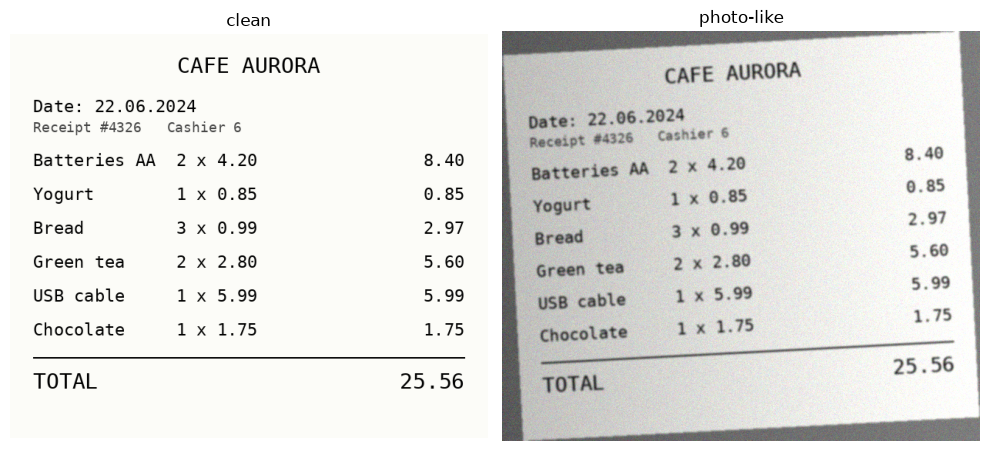

GOLD: {"store": "CAFE AURORA", "date": "2024-06-22", "items": [{"name": "Batteries AA", "qty": 2, "price": 4.2}, {"name": "Yogurt", "qty": 1, "price": 0.85}, {"name": "Bread", "qty": 3, "price": 0.99}, {"name": "Green tea", "qty": 2, "price": 2.8}, {"name": "USB cable", "qty": 1, "price": 5.99}, {"name": "Chocolate", "qty": 1, "price": 1.75}], "total": 25.56}
PRED (clean): {"store":"CAFE AURORA","date":"2024-06-22","items":[{"name":"Batteries AA","qty":2,"price":4.2},{"name":"Yogurt","qty":1,"price":0.85},{"name":"Bread","qty":3,"price":0.99},{"name":"Green tea","qty":2,"price":2.8},{"name":"USB cable","qty":1,"price":5.99},{"name":"Chocolate","qty":1,"price":1.75}], "total":25.56}


In [ ]:
img0, gold0 = make_receipt(1000)
fig, ax = plt.subplots(1, 2, figsize=(10, 5.5))
ax[0].imshow(img0); ax[0].axis("off"); ax[0].set_title("clean")
ax[1].imshow(photo_like(img0, 0)); ax[1].axis("off"); ax[1].set_title("photo-like")
plt.tight_layout(); plt.show()
print("GOLD:", json.dumps(gold0, ensure_ascii=False))
print("PRED (clean):", REC[(REC.k == 0) & (REC.condition == "clean")].raw.iloc[0][:1500])

На что смотреть в результатах:

- В сохранённом прогоне (2 чека) на чистых изображениях всё извлечено верно, на «фотографиях» JSON по-прежнему валиден, а F1 по позициям падает до 0.5: ошибки появляются в названиях и ценах, сумма позиций перестаёт сходиться с итогом в половине случаев.
- Полезный урок из отладки этого блокнота: при запросе «верни JSON» модель выдавала JSON с отступами, и на длинном чеке ответ обрезался по `max_new_tokens` — получался невалидный JSON. Требование компактного JSON в одну строку и запас по длине ответа исправили это. Проверяйте, не упирается ли генерация в лимит токенов.
- Валидность JSON у современных instruct-моделей обычно близка к 100%. Ошибки чаще смысловые: перепутанная цена за единицу и сумма по строке, пропущенная позиция, дата в исходном формате.
- Поле `total` модель часто читает верно, даже когда ошибается в позициях: число крупное и стоит рядом со словом TOTAL.
- Проверка согласованности ловит часть ошибок без эталона. Если сумма позиций не равна итогу, ответ стоит отправить на повторную генерацию или человеку.
- В продакшене JSON дополнительно проверяют по схеме (например, Pydantic). Также можно использовать ограниченное декодирование (constrained decoding), которое не даёт модели сгенерировать невалидный JSON. Но смысловых ошибок оно не исправляет.

## 8. Подсчёт объектов

Нарисуем от 1 до 12 кругов одного цвета, сначала без перекрытий, затем с перекрытиями, как в BlindTest ([Rahmanzadehgervi et al.](https://arxiv.org/abs/2407.06581)). Метрики — точное совпадение и средняя абсолютная ошибка.

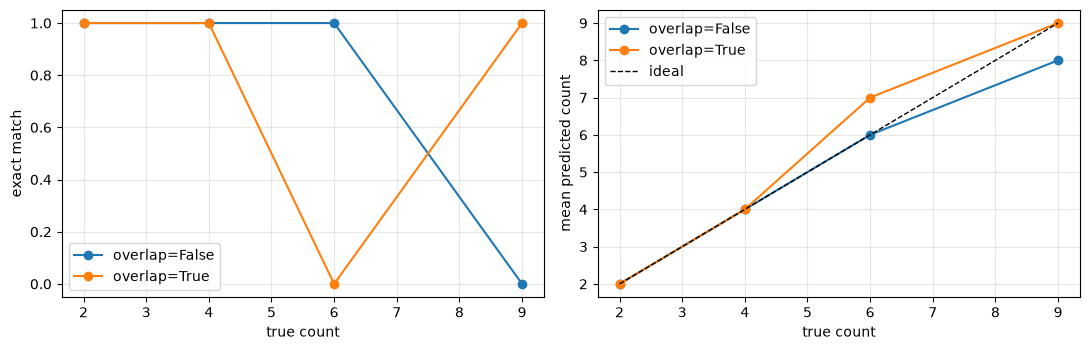

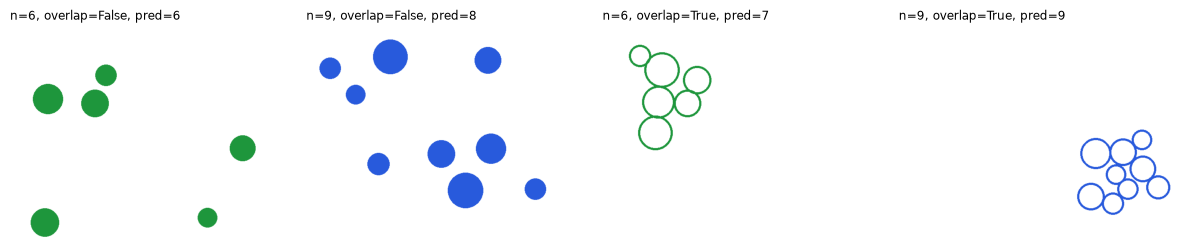

,exact,abs err
overlap,,
False,0.75,0.25
True,0.75,0.25


In [ ]:
COLORS = [(220, 40, 40), (40, 90, 220), (30, 150, 60), (230, 150, 20)]
def circles_image(n, seed, overlap=False, W=640, H=480):
    r = random.Random(seed)
    img = Image.new("RGB", (W, H), "white"); d = ImageDraw.Draw(img)
    col = r.choice(COLORS); placed = []
    while len(placed) < n:
        rad = r.randint(22, 40); x = r.randint(rad + 5, W - rad - 5); y = r.randint(rad + 5, H - rad - 5)
        ok = all(math.hypot(x - a, y - b) > (0.9 * (rad + c) if overlap else rad + c + 8) for a, b, c in placed)
        if overlap and placed:
            ok = ok and min(math.hypot(x - a, y - b) - rad - c for a, b, c in placed) < 0
        if ok or (overlap and not placed):
            placed.append((x, y, rad))
    for x, y, rad in placed:
        if overlap:
            d.ellipse((x - rad, y - rad, x + rad, y + rad), outline=col, width=5)
        else:
            d.ellipse((x - rad, y - rad, x + rad, y + rad), fill=col)
    return img

WORDS = {w: i for i, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen".split())}
def parse_int(text):
    m = re.search(r"\d+", text)
    if m:
        return int(m.group(0))
    for w in tok(text):
        if w in WORDS:
            return WORDS[w]
    return -1

COUNT_NS = [2, 4, 6, 9] if FAST_DEV_RUN else list(range(1, 13))
COUNT_SEEDS = n_(3, 1)
def run_counting(m=None, p=None, mid=None, overlaps=(False, True)):
    rows = []
    for ov in overlaps:
        for n in COUNT_NS:
            for s in range(COUNT_SEEDS):
                img = circles_image(n, 10 * n + s, ov)
                out = ask(img, "How many circles are in the image? Answer with a number only.", f"cnt{n}_{s}_{ov}", 4, 512, m=m, p=p, mid=mid)
                k = parse_int(out["text"])
                rows.append({"n": n, "overlap": ov, "pred": k, "exact": float(k == n), "abs err": abs(k - n)})
    return pd.DataFrame(rows)

CNT = run_counting()
for ov, g in CNT.groupby("overlap"):
    record("counting circles", f"exact, overlap={ov}", g.exact)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for ov, g in CNT.groupby("overlap"):
    gg = g.groupby("n").mean(numeric_only=True)
    ax[0].plot(gg.index, gg.exact, "o-", label=f"overlap={ov}")
    ax[1].plot(gg.index, gg.pred, "o-", label=f"overlap={ov}")
ax[1].plot(COUNT_NS, COUNT_NS, "k--", lw=1, label="ideal")
ax[0].set_xlabel("true count"); ax[0].set_ylabel("exact match"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("true count"); ax[1].set_ylabel("mean predicted count"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
show_images([(circles_image(n, 10 * n, ov), f"n={n}, overlap={ov}, pred={CNT[(CNT.n == n) & (CNT.overlap == ov)].pred.iloc[0]}")
             for ov in (False, True) for n in COUNT_NS[-2:]], ncols=4, size=3.0)
CNT.groupby("overlap")[["exact", "abs err"]].mean().round(3)

Подсчёт — одна из самых устойчивых слабостей VLM. Причины:

- склейка соседних патчей (2×2 в Qwen3-VL, pixel shuffle в InternVL и SmolVLM) смешивает признаки соседних объектов в одном токене;
- в данных для обучения точные числа объектов редки, а «несколько», «группа» — часты;
- у модели нет явной процедуры перебора объектов. Она выдаёт число одним токеном, без пошагового пересчёта.

В сохранённом CPU-прогоне всего 4 изображения, точный ответ в 3 из 4 и с перекрытием, и без: 9 разнесённых кругов модель посчитала как 8, 6 перекрывающихся контуров — как 7. По 4 примерам зависимость от числа объектов не оценить; на GPU выборка больше.

Описанная в литературе картина: малые числа (до 4–5) распознаются хорошо, дальше ошибка растёт и ответы смещаются к «круглым» числам. С перекрытием качество падает раньше. Практические обходные пути: детектор или сегментатор плюс подсчёт боксов (лекции 2 и 3), запрос координат каждого объекта (Qwen-VL умеет выдавать боксы) или разбиение изображения на части.

## 9. Пространственные отношения

Нарисуем красный круг и синий квадрат в одном из четырёх отношений плюс серые фигуры-отвлекатели. Для каждого изображения зададим три вопроса:

- верное утверждение «да/нет» (правильный ответ yes);
- противоположное утверждение (правильный ответ no);
- открытый вопрос с выбором из left / right / above / below.

Согласованность — доля изображений, на которых оба вопроса «да/нет» отвечены верно. Модель, которая всегда говорит «yes», получит 50% по отдельным вопросам и 0% по согласованности.

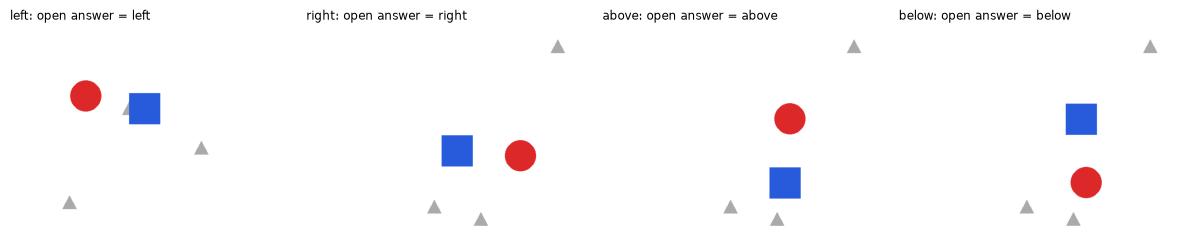

,yes/no true,yes/no opposite,consistent,open
relation,,,,
above,1.0,0.0,0.0,1.0
below,1.0,1.0,1.0,1.0
left,1.0,1.0,1.0,1.0
right,1.0,1.0,1.0,1.0


In [ ]:
OPP = {"left": "right", "right": "left", "above": "below", "below": "above"}
PHRASE = {"left": "to the left of", "right": "to the right of", "above": "above", "below": "below"}
def spatial_image(rel, seed, W=640, H=480):
    r = random.Random(seed)
    img = Image.new("RGB", (W, H), "white"); d = ImageDraw.Draw(img)
    for _ in range(3):
        x, y = r.randint(30, W - 30), r.randint(30, H - 30)
        d.polygon([(x, y - 18), (x - 16, y + 12), (x + 16, y + 12)], fill=(170, 170, 170))
    cx, cy = r.randint(200, 440), r.randint(160, 320); dist = r.randint(130, 170)
    dx, dy = {"left": (-dist, 0), "right": (dist, 0), "above": (0, -dist), "below": (0, dist)}[rel]
    jx, jy = (0, r.randint(-30, 30)) if rel in ("left", "right") else (r.randint(-30, 30), 0)
    ax_, ay_ = cx + dx // 2 + jx, cy + dy // 2 + jy      # красный круг
    bx_, by_ = cx - dx // 2, cy - dy // 2                # синий квадрат
    d.ellipse((ax_ - 35, ay_ - 35, ax_ + 35, ay_ + 35), fill=(220, 40, 40))
    d.rectangle((bx_ - 35, by_ - 35, bx_ + 35, by_ + 35), fill=(40, 90, 220))
    return img

N_SP = n_(10, 1)
def run_spatial(m=None, p=None, mid=None):
    rows = []
    for rel in ["left", "right", "above", "below"]:
        for s in range(N_SP):
            img = spatial_image(rel, 100 * s + len(rel))
            a1 = yes_no(ask(img, f"Is the red circle {PHRASE[rel]} the blue square? Answer yes or no.", f"sp{rel}{s}a", 3, 512, m=m, p=p, mid=mid)["text"])
            a2 = yes_no(ask(img, f"Is the red circle {PHRASE[OPP[rel]]} the blue square? Answer yes or no.", f"sp{rel}{s}b", 3, 512, m=m, p=p, mid=mid)["text"])
            o = ask(img, "Where is the red circle relative to the blue square? Answer with one word: left, right, above, or below.", f"sp{rel}{s}c", 4, 512, m=m, p=p, mid=mid)["text"].lower()
            rows.append({"relation": rel, "yes/no true": float(a1 == "yes"), "yes/no opposite": float(a2 == "no"),
                         "consistent": float(a1 == "yes" and a2 == "no"), "open": float(rel in o), "open answer": o})
    return pd.DataFrame(rows)

SP = run_spatial()
record("spatial relations", "consistency (both yes/no right)", SP.consistent)
record("spatial relations", "open question accuracy", SP.open)
show_images([(spatial_image(rel, len(rel)), f"{rel}: open answer = {SP[SP.relation == rel]['open answer'].iloc[0]}") for rel in OPP], ncols=4, size=3.0)
SP.groupby("relation")[["yes/no true", "yes/no opposite", "consistent", "open"]].mean().round(2)

В сохранённом прогоне открытый вопрос отвечен верно во всех четырёх случаях, но для отношения «above» модель ответила «yes» и на верное утверждение, и на противоположное («Is the red circle below the blue square?»). Согласованность 75% при 100% на открытом вопросе — пример того, почему одной accuracy мало: модель называет отношение правильно, но соглашается с ложным утверждением. На простой синтетике с двумя крупными объектами современные модели обычно справляются хорошо. Это полезный контроль: если модель ошибается даже здесь, проблема в базовом восприятии. В исследовании [What's Up](https://arxiv.org/abs/2310.19785) на реальных фотографиях с одной и той же парой предметов в разных положениях модели показывали около 56% против 99% у людей. Трудности там создают реальные сцены, перспектива и мелкие объекты.

Чтобы усложнить тест, уменьшите фигуры, добавьте одинаковые отвлекатели (два красных круга) или спросите об отношениях «за» и «перед». Это хорошее задание для самостоятельной работы.

## 10. LLM-as-judge: проверяем судью

Модель-судья удобна, когда эталона нет или он не покрывает все верные ответы. Но судья — тоже модель со своими ошибками. Проверим его на парах, где правильный ответ известен заранее. Судьёй будет та же VLM, она видит изображение:

- swap: человеческая подпись против той же подписи с заменённым объектом или атрибутом (dog → cat, man → woman, black → white). Лучше — оригинал;
- verbosity: человеческая подпись против той же подписи с добавленной ложной деталью («while a hot air balloon floats in the sky above»). Лучше — оригинал, хотя второй вариант длиннее и «богаче»;
- self: подпись, сгенерированная этой же моделью, против человеческой. Правильного ответа нет, но смещение в пользу «своего» текста известно ([Zheng et al.](https://arxiv.org/abs/2306.05685)).

Каждую пару предъявляем дважды, меняя порядок A/B. Решение, которое меняется при перестановке, — это позиционное смещение, а не суждение о качестве.

In [ ]:
SWAPS = [("dog", "cat"), ("dogs", "cats"), ("man", "woman"), ("boy", "girl"), ("girl", "boy"), ("woman", "man"),
         ("black", "white"), ("white", "black"), ("red", "blue"), ("blue", "red"), ("water", "sand"), ("snow", "grass")]
def corrupt(c):
    for a, b in SWAPS:
        if re.search(rf"\b{a}\b", c):
            return re.sub(rf"\b{a}\b", b, c, count=1)
    return None

JUDGE_PROMPT = ("You are evaluating captions for this image.\nCaption A: {a}\nCaption B: {b}\n"
                "Which caption describes the image more accurately? Answer with a single letter: A or B.")
def judge(img, a, b, key, m=None, p=None, mid=None):
    t = ask(img, JUDGE_PROMPT.format(a=a, b=b), key, 3, 512, m=m, p=p, mid=mid)["text"].strip().upper()
    return "A" if t.startswith("A") else ("B" if t.startswith("B") else "?")

N_J = n_(30, 3)
pairs = []
for i in range(0, 1000, 7):
    c0 = f8k_caps[i][0].rstrip(" .")
    bad = corrupt(c0)
    if bad:
        pairs.append({"i": i, "type": "swap", "good": c0, "other": bad})
    if len([p_ for p_ in pairs if p_["type"] == "swap"]) >= N_J:
        break
for i in [p_["i"] for p_ in pairs[:N_J]]:
    c0 = f8k_caps[i][0].rstrip(" .")
    pairs.append({"i": i, "type": "verbosity", "good": c0, "other": c0 + " while a hot air balloon floats in the sky above"})
for i in cap_idx[:N_J]:
    own = ask(to_pil(f8k.image[i]), SHORT, f"f8k{i}", max_new_tokens=40, max_tokens=512)["text"].rstrip(" .")
    pairs.append({"i": i, "type": "self", "good": f8k_caps[i][0].rstrip(" ."), "other": own})

j_rows = []
for k, pr in enumerate(pairs):
    img = to_pil(f8k.image[pr["i"]])
    v1 = judge(img, pr["good"], pr["other"], f"j{k}ab")   # good = A
    v2 = judge(img, pr["other"], pr["good"], f"j{k}ba")   # good = B
    j_rows.append({"type": pr["type"], "good first": float(v1 == "A"), "good second": float(v2 == "B"),
                   "consistent": float((v1 == "A") == (v2 == "B")), "picked A": ((v1 == "A") + (v2 == "A")) / 2,
                   "v1": v1, "v2": v2, "good": pr["good"], "other": pr["other"]})
J = pd.DataFrame(j_rows)
J["accuracy (both orders)"] = (J["good first"] + J["good second"]) / 2
for t, g in J.groupby("type", sort=False):
    record("LLM-as-judge", f"{t}: accuracy over both orders" if t != "self" else "self: prefers human caption", g["accuracy (both orders)"])
J.groupby("type", sort=False)[["good first", "good second", "accuracy (both orders)", "consistent", "picked A"]].mean().round(2)

,good first,good second,accuracy (both orders),consistent,picked A
type,,,,,
swap,1.0,1.0,1.0,1.0,0.5
verbosity,1.0,1.0,1.0,1.0,0.5
self,0.0,0.0,0.0,1.0,0.5


In [ ]:
for t in ["swap", "verbosity"]:
    r = J[J.type == t].iloc[0]
    print(f"[{t}] A/B → {r.v1}, B/A → {r.v2}\n  good : {r.good}\n  other: {r.other}")

[swap] A/B → A, B/A → B
  good : The dogs are in the snow in front of a fence
  other: The cats are in the snow in front of a fence
[verbosity] A/B → A, B/A → B
  good : The dogs are in the snow in front of a fence
  other: The dogs are in the snow in front of a fence while a hot air balloon floats in the sky above


Как интерпретировать таблицу:

- `good first` и `good second` — доля верных решений, когда правильная подпись стоит первой и второй. Большая разница между ними — позиционное смещение. Колонка `picked A` около 0.5 означает, что смещения к первой позиции нет.
- Пары swap проверяют, видит ли судья изображение. Пары verbosity проверяют, не путает ли он подробность с точностью.
- В сохранённом прогоне судья верно решил все пары swap и verbosity в обоих порядках, а в парах self во всех трёх случаях выбрал собственную подпись, а не человеческую. Подписи модели подробнее человеческих, поэтому это может быть и реальное качество, и самопредпочтение, и смещение к длине — ровно поэтому нужна разметка людьми.
- Для пар self в колонке `accuracy (both orders)` стоит доля случаев, когда предпочтена человеческая подпись. Значение заметно ниже 0.5 может означать как реальное превосходство модели, так и самопредпочтение. Без людей это не различить, поэтому судья не должен оценивать сам себя.

Минимальный протокол для LLM-as-judge в курсовом проекте:

1. Разметить вручную 50–100 примеров и посчитать согласие судьи с людьми (accuracy или κ Коэна).
2. Всегда оценивать в обоих порядках и считать ничьей несогласованные решения.
3. Давать судье рубрику и эталон, если он есть.
4. Использовать судью другого семейства или более сильного, чем оцениваемые модели.

## 11. Переход 4B → 2B: что теряем

Сравним две модели на одних и тех же примерах: POPE, TextVQA при 1024 токенах, синтетический OCR, чеки, подсчёт, пространственные отношения. Для каждой модели заново измеряем пиковую память и среднее время ответа. Раздел выполняется только на GPU. Текущая модель выгружается, поэтому ячейки разделов 2–10 после него перезапускать не нужно: их ответы сохранены в кэше.

In [ ]:
def task_metrics(m, p, mid):
    out = {}
    pr, _ = run_pope(pope_sub, m, p, mid, blind_too=False)
    out["POPE acc"] = np.mean(np.array(pr) == pope_sub.answer.values)
    tv = run_tvqa([1024], m, p, mid, blind_too=False); out["TextVQA acc (1024 tok)"] = tv.acc.mean()
    oc = run_ocr([1024], m, p, mid); out["synthetic OCR exact (1024 tok)"] = oc.exact.mean()
    rc = run_receipts(m, p, mid, conditions=[("clean", None), ("photo", None)]); out["receipt item F1"] = rc.item_F1.mean()
    cn = run_counting(m, p, mid, overlaps=(False,)); out["counting exact"] = cn.exact.mean()
    sp = run_spatial(m, p, mid); out["spatial consistency"] = sp.consistent.mean()
    secs = [v["seconds"] for k, v in CACHE.items() if k[0] == mid and v["n_new"] <= 16]
    out["mean latency, short answers, s"] = np.mean(secs)
    torch.cuda.reset_peak_memory_stats()
    generate(m, p, probe_image(), "Describe this image.", max_new_tokens=64)
    out["peak VRAM (probe), GiB"] = torch.cuda.max_memory_allocated() / 2**30
    out["weights, GiB"] = m.get_memory_footprint() / 2**30
    return out

if RUN_MODEL_COMPARISON:
    first_id = MODEL_ID
    M1 = task_metrics(model, proc, MODEL_ID)
    other = [c for c in MODEL_CANDIDATES if c != MODEL_ID][0]
    model = proc = None; free_model()
    model2, proc2 = load_vlm(other)
    M2 = task_metrics(model2, proc2, other)
    COMP = pd.DataFrame({first_id.split("/")[-1]: M1, other.split("/")[-1]: M2})
    COMP["Δ (2nd − 1st)"] = COMP.iloc[:, 1] - COMP.iloc[:, 0]
    display(COMP.round(3))
else:
    print("Сравнение пропущено: нужен GPU (RUN_MODEL_COMPARISON = False).")

Сравнение пропущено: нужен GPU (RUN_MODEL_COMPARISON = False).


Ожидаемая картина при переходе 4B → 2B (в сохранённых выводах этого раздела нет: он выполняется только на GPU, проверьте её сами):

- память весов сокращается примерно вдвое, время ответа — меньше чем вдвое. На коротких ответах заметную долю времени занимают визуальный энкодер и накладные расходы, а он у обеих моделей одинаковый;
- сильнее всего теряются задачи, где нужно рассуждение и следование формату: извлечение JSON и сложные вопросы TextVQA;
- восприятие, которое зависит от визуального энкодера (простой OCR, крупные объекты), страдает меньше: энкодер у моделей общий по архитектуре.

Отсюда практический порядок экономии памяти: сначала число визуальных токенов, `max_new_tokens` и батч, потом 4-bit, и только потом меньшая модель. Решение о переходе принимается по метрикам своей задачи, а не по общему рейтингу.

## 12. Итоги практики

In [ ]:
SUMMARY = pd.DataFrame(RESULTS)
SUMMARY

,model,task,metric,value,ci95,n
0,Qwen3-VL-2B-Instruct,captioning (Flickr8k),"CIDEr-D, model, short",0.2,[0.0; 0.6],3
1,Qwen3-VL-2B-Instruct,captioning (Flickr8k),"CLIPScore, model, short",0.9,[0.7; 1.0],3
2,Qwen3-VL-2B-Instruct,captioning (Flickr8k),"CIDEr-D, model, detailed",0.0,[0.0; 0.0],3
3,Qwen3-VL-2B-Instruct,captioning (Flickr8k),"CLIPScore, model, detailed",0.8,[0.7; 0.9],3
4,Qwen3-VL-2B-Instruct,POPE adversarial,accuracy,79.2,[62.5; 95.8],24
5,Qwen3-VL-2B-Instruct,POPE adversarial,"accuracy, blind",45.8,[25.0; 66.7],24
6,Qwen3-VL-2B-Instruct,caption hallucination (POPE images),share of captions with absent object,0.0,[0.0; 0.0],3
7,Qwen3-VL-2B-Instruct,TextVQA,"VQA acc, budget=256",75.0,[25.0; 100.0],4
8,Qwen3-VL-2B-Instruct,TextVQA,"VQA acc, budget=1024",75.0,[25.0; 100.0],4
9,Qwen3-VL-2B-Instruct,TextVQA,"VQA acc, budget=blind",0.0,[0.0; 0.0],4


| Наблюдение | Раздел |
|---|---|
| Бюджет памяти оценивается по конфигурации, но пик проверяется на самом тяжёлом запросе (memory probe) | 1 |
| Число визуальных токенов $=$ (H/32)·(W/32) — главный рычаг стоимости; на OCR оно же — рычаг качества | 2, 6 |
| NF4 точнее равномерной INT4 при той же памяти, двойное квантование сокращает накладные расходы | 2.3 |
| CIDEr наказывает подробные описания, CLIPScore не видит текст после 77 токенов | 4 |
| Галлюцинации проверяются и вопросами «да/нет», и свободными описаниями; нужен слепой контроль: без изображения модель отвечала «yes» в 96% случаев | 5 |
| Мелкий текст требует разрешения: в прогоне шрифт 10 px при 256 токенах читается с CER 0.62, при 1024 — без ошибок | 6 |
| Для extraction нужны метрики по полям и проверки согласованности, а не только валидность JSON | 7 |
| Подсчёт ошибается на ±1 уже при 6–9 объектах; зависимость от числа и перекрытия видна на больших выборках | 8 |
| Судью нужно проверять: оба порядка, контрольные пары, согласие с людьми | 10 |
| Меньшая модель — последний рычаг; потери зависят от задачи | 11 |

# Контрольные вопросы

1. Нарисуйте схему «визуальный энкодер → проектор → LLM». Какие тензоры передаются между блоками и какие у них размерности для Qwen3-VL-2B и изображения 448×448?
2. Почему функцию потерь VLM считают только по токенам ответа? К какому нежелательному поведению это может привести, если ответы угадываются по вопросу?
3. Сравните линейный проектор, pixel shuffle и Q-Former по числу выходных токенов, сохранению геометрии и пригодности для OCR.
4. Сколько визуальных токенов получит изображение 1920×1080 в LLaVA-1.5, в InternVL (тайлы 448, не более 6 тайлов, миниатюра) и в Qwen3-VL (32 пикселя на токен, без ограничения `max_pixels`)?
5. Почему авторы SmolVLM используют pixel shuffle с $r = 4$, а InternVL — с $r = 2$?
6. Чем DeepStack в Qwen3-VL отличается от добавления визуальных токенов во вход LLM?
7. Выведите формулу размера KV-кэша. Сколько памяти займёт кэш Qwen3-VL-4B для 8 запросов по 2000 токенов в FP16?
8. Почему на T4 вычисления в 4-bit режиме ведут в FP16, а не в BF16? Какие симптомы могут указывать на переполнение FP16?
9. Опишите алгоритм memory probe. Почему оценки «веса + KV-кэш» недостаточно?
10. Как строятся 16 уровней NF4? Почему они несимметричны? Сколько бит на параметр экономит double quantization при блоке 64?
11. Ускоряет ли 4-bit квантизация bitsandbytes вычисления? Объясните отдельно для prefill и для генерации.
12. Почему подробное правильное описание может получить CIDEr ниже, чем короткое? Что в этой ситуации покажет CLIPScore?
13. Модель отвечает «yes» на 95% вопросов POPE. Какие у неё будут accuracy, precision и recall на сбалансированной выборке, если на вопросы с ответом «yes» она всегда права?
14. Зачем нужен слепой baseline? Что показала MMStar о бенчмарке MMMU?
15. Чем ANLS лучше точного совпадения для OCR-ответов? Посчитайте ANLS для ответа «PERMM» при эталоне «PERM».
16. Какие уровни метрик вы бы использовали для извлечения JSON из счетов? Почему одной метрики «JSON совпал целиком» мало?
17. Назовите три смещения LLM-as-judge и способ проверить каждое.
18. Почему проверка согласованности (вопросы «A левее B?» и «B левее A?») информативнее accuracy в тестах на пространственные отношения?
19. Почему случайные буквенно-цифровые коды — лучший тест OCR, чем словарные слова?
20. Вы перешли с 4B на 2B из-за нехватки памяти. На каких задачах вы ожидаете наибольшую потерю качества и как это проверить?

# Задания

Задание 1. Бюджет токенов и памяти (без GPU). Для изображений 640×480, 1920×1080 и 2480×3508 посчитайте число визуальных токенов в LLaVA-1.5, InternVL3 (до 12 тайлов) и Qwen3-VL с `MAX_VISUAL_TOKENS = 1024` и без ограничения. Для каждого случая оцените KV-кэш Qwen3-VL-4B и сделайте вывод, какой режим подходит для T4.

Задание 2. Memory probe. Задайте в конфигурации `VRAM_BUDGET_GB = 3` и убедитесь, что блокнот переходит с 4B на 2B. Затем найдите максимальный `MAX_VISUAL_TOKENS`, при котором 4B проходит probe при бюджете 4 ГиБ. Приведите таблицу «бюджет токенов → пик памяти».

Задание 3. Квантизация. В разделе 2.3 замените слой `down_proj` на слой внимания (`self_attn.q_proj`) и на слой визуального энкодера. Сравните ошибку NF4 и INT4 и эксцесс распределения весов. Где NF4 выигрывает сильнее? Объясните связь с формой распределения.

Задание 4. Captioning. Увеличьте выборку Flickr8k до 200 изображений и посчитайте CIDEr и CLIPScore для трёх промптов: короткий, подробный и «одно предложение в стиле Flickr8k» (few-shot с двумя примерами подписей). Сравните с human baseline. Какой промпт «обыгрывает» метрику и почему это не означает лучшего качества?

Задание 5. Галлюцинации. Прогоните POPE в режимах random, popular и adversarial (по 300 вопросов) и постройте таблицу accuracy, F1 и доли «yes» с доверительными интервалами. Затем добавьте к промпту «If the object is not present, answer No.» и проверьте, меняется ли доля «yes».

Задание 6. OCR и разрешение. Расширьте синтетический OCR-тест: 3 шрифта, 6 размеров, 4 бюджета токенов. Постройте тепловую карту CER и найдите минимальную высоту символа в пикселях исходного изображения, при которой CER < 5%, для каждого бюджета. Согласуется ли результат с размером визуального токена 32×32?

Задание 7. Structured extraction. Добавьте в генератор чеков поле даты и скидку, а также шум (поворот на 2–5°, JPEG-артефакты). Сравните два промпта: «верни JSON» и «верни JSON по схеме» с JSON Schema в промпте. Отчитайтесь по пяти уровням метрик из раздела 11.4.

Задание 8. LLM-as-judge. Соберите 30 пар «правильный ответ / ответ с внедрённой ошибкой» трёх типов (объект, цвет, число). Оцените текстового судью (без изображения) и мультимодального (с изображением) в обоих порядках. Посчитайте точность, согласованность и κ Коэна с вашей собственной разметкой.

Задание 9 (проектное). Для задачи из вашей предметной области (например, чтение показаний счётчиков, разбор накладных, описание снимков с БПЛА) соберите 50–100 размеченных примеров, выберите метрики, оцените Qwen3-VL-2B и 4B (или SmolVLM2-2.2B из лабораторной работы) и напишите отчёт на одну страницу: протокол, числа с интервалами, примеры ошибок по категориям раздела 14.

# Источники

Архитектуры VLM

1. Liu H. et al. Visual Instruction Tuning (LLaVA), 2023. https://arxiv.org/abs/2304.08485
2. Liu H. et al. Improved Baselines with Visual Instruction Tuning (LLaVA-1.5), 2023. https://arxiv.org/abs/2310.03744
3. LLaVA-NeXT: Improved reasoning, OCR, and world knowledge, 2024. https://llava-vl.github.io/blog/2024-01-30-llava-next/
4. Bai J. et al. Qwen-VL, 2023. https://arxiv.org/abs/2308.12966
5. Wang P. et al. Qwen2-VL, 2024. https://arxiv.org/abs/2409.12191
6. Bai S. et al. Qwen2.5-VL Technical Report, 2025. https://arxiv.org/abs/2502.13923
7. Qwen Team. Qwen3-VL Technical Report, 2025. https://arxiv.org/abs/2511.21631
8. Модели Qwen3-VL-4B-Instruct и Qwen3-VL-2B-Instruct. https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct, https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct
9. Qwen3.5 small models: карточка модели и анонс. https://huggingface.co/unsloth/Qwen3.5-4B, https://x.com/Alibaba_Qwen/status/2028460046510965160
10. Chen Z. et al. How Far Are We to GPT-4V? (InternVL 1.5), 2024. https://arxiv.org/abs/2404.16821
11. Zhu J. et al. InternVL3, 2025. https://arxiv.org/abs/2504.10479
12. Wang W. et al. InternVL3.5, 2025. https://arxiv.org/abs/2508.18265
13. Marafioti A. et al. SmolVLM: Redefining small and efficient multimodal models, 2025. https://arxiv.org/abs/2504.05299
14. Li J. et al. BLIP-2, 2023. https://arxiv.org/abs/2301.12597
15. Alayrac J.-B. et al. Flamingo, 2022. https://arxiv.org/abs/2204.14198
16. Liu Z. et al. NVILA: Efficient Frontier Visual Language Models, 2024. https://arxiv.org/abs/2412.04468
17. Tong S. et al. Eyes Wide Shut? Exploring the Visual Shortcomings of Multimodal LLMs (MMVP), 2024. https://arxiv.org/abs/2401.06209

Квантизация и память

18. Dettmers T. et al. QLoRA: Efficient Finetuning of Quantized LLMs, 2023. https://arxiv.org/abs/2305.14314
19. Dettmers T. et al. LLM.int8(), 2022. https://arxiv.org/abs/2208.07339
20. Frantar E. et al. GPTQ, 2022. https://arxiv.org/abs/2210.17323
21. Lin J. et al. AWQ, 2023. https://arxiv.org/abs/2306.00978
22. bitsandbytes, функция create_normal_map. https://github.com/bitsandbytes-foundation/bitsandbytes/blob/main/bitsandbytes/functional.py
23. NVIDIA T4 Tensor Core GPU: datasheet и страница продукта. https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/tesla-t4/t4-tensor-core-datasheet-951643.pdf, https://www.nvidia.com/en-us/data-center/tesla-t4/
24. vlm-inference-profiler (Qwen2.5-VL-7B в NF4 на T4). https://github.com/varuntej07/vlm-inference-profiler
25. Пример запуска Qwen3-VL-4B в 4-bit (2.62 ГБ). https://seanneilan.com/posts/scraping-target-with-qwen/

Метрики и бенчмарки

26. Vedantam R. et al. CIDEr, 2015. https://arxiv.org/abs/1411.5726
27. Hessel J. et al. CLIPScore, 2021. https://arxiv.org/abs/2104.08718
28. Rohrbach A. et al. Object Hallucination in Image Captioning (CHAIR), 2018. https://arxiv.org/abs/1809.02156
29. Li Y. et al. Evaluating Object Hallucination in LVLMs (POPE), 2023. https://arxiv.org/abs/2305.10355
30. Antol S. et al. VQA: Visual Question Answering, 2015. https://arxiv.org/abs/1505.00468
31. Singh A. et al. Towards VQA Models That Can Read (TextVQA), 2019. https://arxiv.org/abs/1904.08920
32. Mathew M. et al. DocVQA, 2020. https://arxiv.org/abs/2007.00398
33. Liu Y. et al. OCRBench, 2023. https://arxiv.org/abs/2305.07895
34. Yue X. et al. MMMU, 2023. https://arxiv.org/abs/2311.16502
35. Liu Y. et al. MMBench, 2023. https://arxiv.org/abs/2307.06281
36. Fu C. et al. MME, 2023. https://arxiv.org/abs/2306.13394
37. Chen L. et al. Are We on the Right Way for Evaluating LVLMs? (MMStar), 2024. https://arxiv.org/abs/2403.20330
38. Lu P. et al. MathVista, 2023. https://arxiv.org/abs/2310.02255
39. Fu X. et al. BLINK, 2024. https://arxiv.org/abs/2404.12390
40. Kamath A. et al. What's "up" with vision-language models?, 2023. https://arxiv.org/abs/2310.19785
41. Rahmanzadehgervi P. et al. Vision Language Models Are Blind, 2024. https://arxiv.org/abs/2407.06581
42. Duan H. et al. VLMEvalKit, 2024. https://arxiv.org/abs/2407.11691
43. Zhang K. et al. LMMs-Eval: Reality Check on the Evaluation of Large Multimodal Models, 2024. https://arxiv.org/abs/2407.12772

LLM-as-judge

44. Zheng L. et al. Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena, 2023. https://arxiv.org/abs/2306.05685
45. Chen D. et al. MLLM-as-a-Judge, 2024. https://arxiv.org/abs/2402.04788

Данные практики

46. POPE (lmms-lab). https://huggingface.co/datasets/lmms-lab/POPE
47. Flickr8k (jxie). https://huggingface.co/datasets/jxie/flickr8k
48. TextVQA (lmms-lab). https://huggingface.co/datasets/lmms-lab/textvqa
49. Репозиторий курса. https://github.com/fmi-ml-courses/computer_vision_2026_students